# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_23_10232026/llm_decision_making_spectrum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [ ]:
! pip install -q igor2

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)
import glob
import pickle


Download data

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1qN-AdhA19oHG3yNo7te7stjzQ_VM1OY_?usp=sharing"

Retrieving folder contents
Processing file 1IgCLQzbzAa0bLQhOvrEErqa1q7qVuDJp eels_ei_trace.pkl
Processing file 1miIUP0M6Yhko255qKCGoswUwqZq0cv7L eels_random_trace.pkl
Processing file 1QpFGNFVC80U2tnFOOaqjEjdTwxI2QWbQ eels_ucb_trace.pkl
Processing file 11qPUBwjyRWKN0DLQgaS2G5Y7lfvk8Rk5 Plasmonic_sets_hackathon.npy
Processing file 1TMwA2uaBMgHbr0FYHrU9SFknZ8Do_HeE trace_P01_eels_.pkl
Processing file 1rSK25XhXesuMGoIsg3kVxKffMchLygSu trace_P03_eels.pkl
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1IgCLQzbzAa0bLQhOvrEErqa1q7qVuDJp
To: /content/day_22/eels_ei_trace.pkl
100% 18.6M/18.6M [00:00<00:00, 109MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1miIUP0M6Yhko255qKCGoswUwqZq0cv7L
To: /content/day_22/eels_random_trace.pkl
100% 18.6M/18.6M [00:00<00:00, 65.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1QpFGNFVC80U2tnFOOaqjEjdTwxI2QWbQ
To: /content/day_22/e

## load data

In [ ]:
fname = "/content/day_22/Plasmonic_sets_hackathon.npy"

raw = np.load(fname, allow_pickle=True)
loadedfile = raw.tolist()

print("Available datasets:", loadedfile.keys())

Available datasets: dict_keys(['0', '1', '2', '3'])


In [ ]:
# Use the same dataset as the previous challenge
data = loadedfile["0"]

image = data["image"]
spectra = data["spectrum image"]
energy = data["energy axis"]

H, W, N_E = spectra.shape

print("Image:", image.shape)
print("Spectral image:", spectra.shape)
print("Energy axis:", energy.shape)

Image: (66, 152)
Spectral image: (66, 152, 4198)
Energy axis: (4198,)


## <font color="purple">**2.**</font> Explore the Spectra

Before clustering, always look at the data.

The structural image tells us **where** each spectrum was measured.  
The spectra tell us **what the local EELS response looks like**.

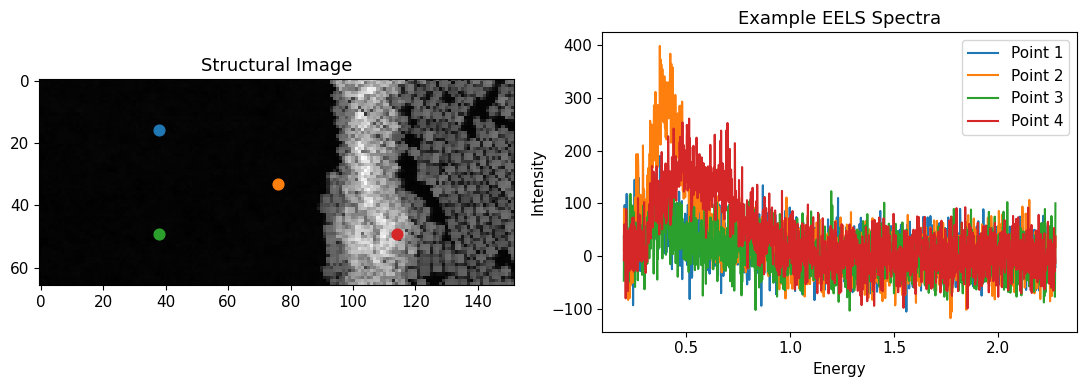

In [ ]:
# Pick a few example locations
positions = [
    (H // 4, W // 4),
    (H // 2, W // 2),
    (3 * H // 4, W // 4),
    (3 * H // 4, 3 * W // 4),
]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].imshow(image, cmap="gray")
ax[0].set_title("Structural Image")

for i, (y, x) in enumerate(positions):
    ax[0].scatter(x, y, s=60)
    ax[1].plot(energy, spectra[y, x], label=f"Point {i + 1}")

ax[1].set_title("Example EELS Spectra")
ax[1].set_xlabel("Energy")
ax[1].set_ylabel("Intensity")
ax[1].legend()

plt.tight_layout()
plt.show()

Traces

In [ ]:
trace_files = [
    "/content/day_22/eels_ei_trace.pkl",
    "/content/day_22/eels_random_trace.pkl",
    "/content/day_22/eels_ucb_trace.pkl",
    "/content/day_22/trace_P01_eels_.pkl",
    "/content/day_22/trace_P03_eels.pkl"
]

traces = {}

for i, fname in enumerate(trace_files):
    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

    print(f"Trace {i}: {fname.split('/')[-1]}")

Trace 0: eels_ei_trace.pkl
Trace 1: eels_random_trace.pkl
Trace 2: eels_ucb_trace.pkl
Trace 3: trace_P01_eels_.pkl
Trace 4: trace_P03_eels.pkl


Understanding the EELS Decision Traces
Each trace contains a sequence of decisions made by an agent while exploring an EELS dataset.

At each decision step, the agent is presented with several possible measurement locations and selects one.

For every step, the recorded information may include:
- candidate_positions — spatial coordinates of all available measurement locations.
- selected_position — index of the candidate selected by the agent.
- selected_spectrum — EELS spectrum measured at the selected location.
- selected_axis — corresponding energy-loss axis (eV).
- step — decision step number.
The four traces represent different decision-making strategies: Expected Improvement (EI), Random Sampling, Upper Confidence Bound (UCB), and PO6.

In [ ]:
TRACE_ID = 4
STEP = 1

trace = traces[TRACE_ID]
step_data = trace["decisions"][STEP - 1]

print("Step:", step_data["step"])

print("Selected candidate position:", step_data["selected_position"])
print("Selected dataset index:", step_data["selected_index"])
print("Selected coordinates:", step_data["selected_coordinates"])

print("Number of candidates:", len(step_data["candidate_indices"]))
print("Candidate indices:", step_data["candidate_indices"])
print("Candidate coordinates:", step_data["candidate_coordinates"])

# print("Selected reward:", step_data["selected_reward"])

print("Selected spectrum shape:", np.shape(step_data["selected_spectrum"]))
print("Energy axis shape:", np.shape(step_data["selected_axis"]))

Step: 1
Selected candidate position: 10
Selected dataset index: 3926
Selected coordinates: [ 25 126]
Number of candidates: 20
Candidate indices: [ 844 7959 7939 3644 6871 2156 2717 5571 6716 9399 3926 6660 3532  642
 3058 1992 1662 7401 3327 5374]
Candidate coordinates: [[  5  84]
 [ 52  55]
 [ 52  35]
 [ 23 148]
 [ 45  31]
 [ 14  28]
 [ 17 133]
 [ 36  99]
 [ 44  28]
 [ 61 127]
 [ 25 126]
 [ 43 124]
 [ 23  36]
 [  4  34]
 [ 20  18]
 [ 13  16]
 [ 10 142]
 [ 48 105]
 [ 21 135]
 [ 35  54]]
Selected spectrum shape: (4198,)
Energy axis shape: (4198,)


VISUALIZE ONE DECISION STEP

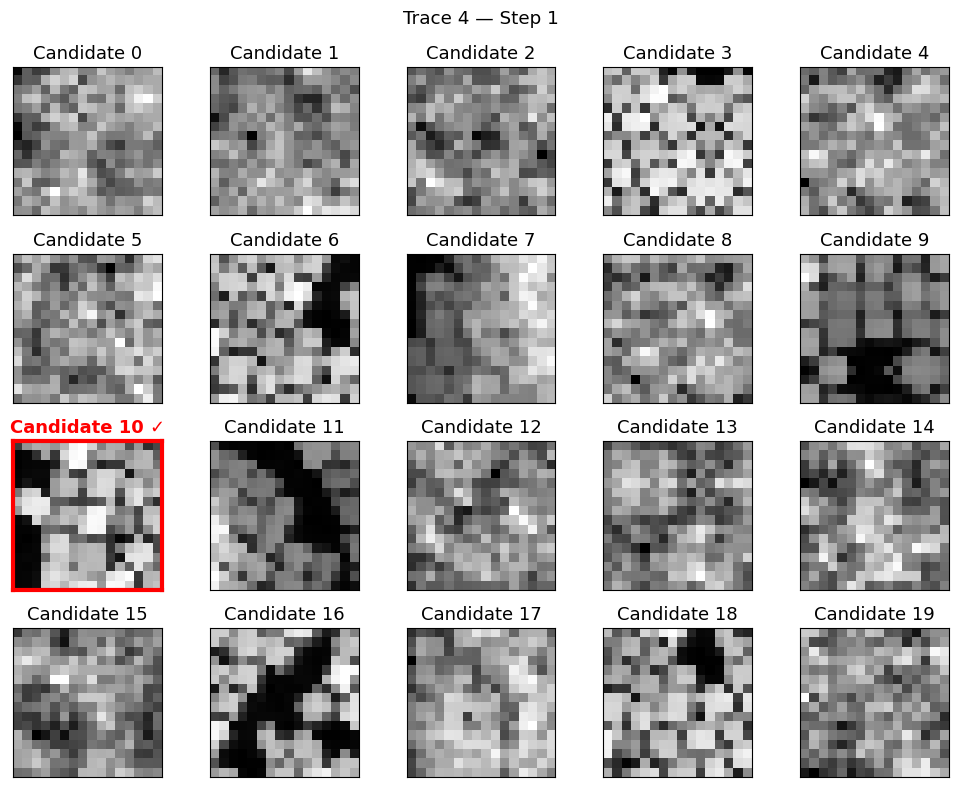

In [ ]:
patches = step_data["candidate_patches"]
selected = step_data["selected_position"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    patch = np.squeeze(patches[i])   # <-- fixes (1,16,16) -> (16,16)

    ax.imshow(
        patch,
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

Show the spectrum

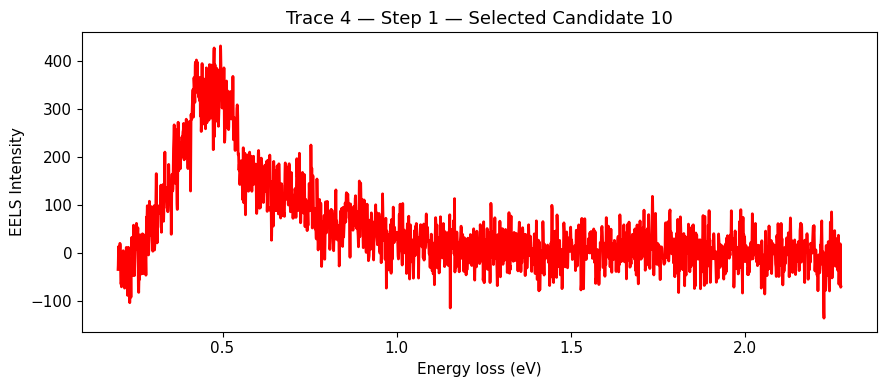

In [ ]:
energy = step_data["selected_axis"]
spectrum = step_data["selected_spectrum"]

plt.figure(figsize=(9, 4))

plt.plot(energy, spectrum, color="red", linewidth=2)

plt.xlabel("Energy loss (eV)")
plt.ylabel("EELS Intensity")
plt.title(f"Trace {TRACE_ID} — Step {STEP} — Selected Candidate {selected}")

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

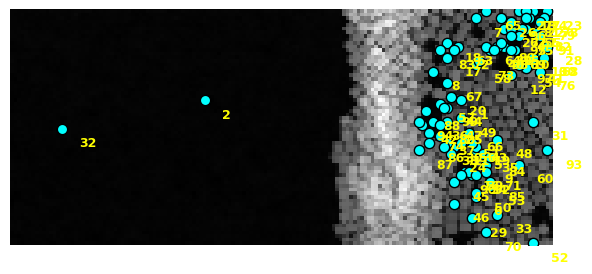

In [ ]:
trace = traces[TRACE_ID]
decisions = trace["decisions"]

xs = [d["selected_coordinates"][1] for d in decisions]
ys = [d["selected_coordinates"][0] for d in decisions]

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(image, cmap="gray")

ax.scatter(
    xs, ys,
    s=55,
    color="cyan",
    edgecolors="black"
)

for i, (x, y) in enumerate(zip(xs, ys)):
    ax.text(
        x + 5,
        y + 5,
        str(decisions[i]["step"]),
        fontsize=9,
        color="yellow",
        weight="bold"
    )

ax.axis("off")
plt.show()

DECISION MAPS FOR 10 TRACES


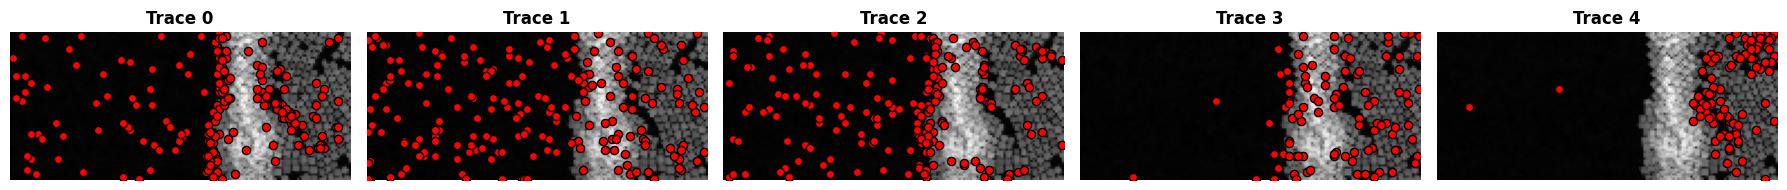

In [ ]:
TRACE_IDS = list(traces.keys())

ncols = 5
nrows = int(np.ceil(len(TRACE_IDS) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 5 * nrows)
)

axes = np.array(axes).flatten()

for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]
    decisions = trace["decisions"]

    xs = [d["selected_coordinates"][1] for d in decisions]
    ys = [d["selected_coordinates"][0] for d in decisions]

    # Original EELS image
    ax.imshow(image, cmap="gray")

    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="red",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")

# Hide unused axes
for ax in axes[len(TRACE_IDS):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Block 1: inspect the data available for decision-rule discovery

import numpy as np
import pandas as pd
from collections import Counter
from pathlib import Path
from IPython.display import display

missing = [name for name in ("data", "traces") if name not in globals()]
if missing:
    raise RuntimeError(
        f"Run the original data-loading cells first. Missing: {missing}"
    )

# Read the original energy axis:
# earlier notebook cells reuse 'energy' for individual spectra.
analysis_image = np.asarray(data["image"])
analysis_spectra = np.asarray(data["spectrum image"])
analysis_energy = np.asarray(data["energy axis"]).reshape(-1)

if (
    analysis_spectra.ndim != 3
    or analysis_image.shape != analysis_spectra.shape[:2]
    or analysis_energy.size != analysis_spectra.shape[-1]
):
    raise ValueError(
        "The image, spectral cube, and energy axis have incompatible shapes."
    )

print("Image shape:", analysis_image.shape)
print("Spectral cube shape:", analysis_spectra.shape)
print("Energy-axis shape:", analysis_energy.shape)

# Keep the original filenames as trace labels.
trace_labels = {
    i: Path(path).stem
    for i, path in enumerate(globals().get("trace_files", []))
}


def preview(value, limit=500):
    """Summarize a stored value without printing large arrays."""
    if isinstance(value, np.ndarray):
        return f"array: shape={value.shape}, dtype={value.dtype}"

    if isinstance(value, dict):
        value = "dictionary fields: " + ", ".join(map(str, value.keys()))

    elif isinstance(value, (list, tuple)):
        return f"{type(value).__name__}: {len(value)} entries"

    text = str(value).replace("\n", " ")
    return text[:limit] + (" ..." if len(text) > limit else "")


summary_rows = []
field_counts = {}
metadata_preview = []

keywords = (
    "prompt", "instruction", "objective", "reward", "model",
    "strategy", "policy", "config", "history", "message",
    "context", "input"
)

for trace_id, record in traces.items():
    label = trace_labels.get(trace_id, f"trace_{trace_id}")
    steps = record.get("decisions", [])

    counts = [
        len(step["candidate_indices"])
        for step in steps
        if step.get("candidate_indices") is not None
    ]

    # Scan every decision, since some fields may appear only in later steps.
    fields = Counter(key for step in steps for key in step)
    field_counts[f"{trace_id}: {label}"] = fields

    summary_rows.append({
        "trace_id": trace_id,
        "trace": label,
        "decisions": len(steps),
        "candidate_sets": len(counts),
        "candidates_min": min(counts) if counts else None,
        "candidates_max": max(counts) if counts else None,
        "steps_with_patches": sum(
            s.get("candidate_patches") is not None for s in steps
        ),
        "steps_with_spectra": sum(
            s.get("selected_spectrum") is not None for s in steps
        ),
    })

    # Preview metadata stored at the trace level.
    for key, value in record.items():
        if key != "decisions":
            metadata_preview.append(
                (label, "trace", key, preview(value))
            )

    # Preview the first available value of relevant decision-level fields.
    for key in fields:
        if any(word in str(key).lower() for word in keywords):
            first = next(
                (s for s in steps if s.get(key) is not None),
                None
            )

            if first is not None:
                scope = f"decision {first.get('step', '?')}"
                metadata_preview.append(
                    (label, scope, key, preview(first[key]))
                )

trace_summary = pd.DataFrame(summary_rows)

decision_field_counts = (
    pd.DataFrame(field_counts)
    .fillna(0)
    .astype(int)
    .sort_index()
)

print("\nTRACE SUMMARY")
display(trace_summary)

print("\nSTORED DECISION FIELDS: number of steps containing each field")
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(decision_field_counts)

print("\nMETADATA PREVIEW")
for label, scope, key, value in metadata_preview:
    print(f"[{label} | {scope}] {key}: {value}")

if not metadata_preview:
    print("No metadata found outside the basic decision fields.")

Image shape: (66, 152)
Spectral cube shape: (66, 152, 4198)
Energy-axis shape: (4198,)

TRACE SUMMARY


,trace_id,trace,decisions,candidate_sets,candidates_min,candidates_max,steps_with_patches,steps_with_spectra
0,0,eels_ei_trace,200,200,20,20,200,200
1,1,eels_random_trace,200,200,20,20,200,200
2,2,eels_ucb_trace,200,200,20,20,200,200
3,3,trace_P01_eels_,100,100,20,20,100,100
4,4,trace_P03_eels,100,100,20,20,100,100



STORED DECISION FIELDS: number of steps containing each field


,0: eels_ei_trace,1: eels_random_trace,2: eels_ucb_trace,3: trace_P01_eels_,4: trace_P03_eels
acquisition,200,200,200,0,0
acquisition_scores,200,200,200,0,0
candidate_coordinates,200,200,200,100,100
candidate_ids,200,200,200,100,100
candidate_indices,200,200,200,100,100
candidate_mode,200,200,200,0,0
candidate_patches,200,200,200,100,100
duration_seconds,199,199,199,0,0
measurement_channels,0,0,0,100,100
n_training,199,199,199,0,0



METADATA PREVIEW
[eels_ei_trace | trace] config: dictionary fields: dataset, files, patch_size, scalarizer, energy_window, nl_fraction, nl_order, acquisition, beta, xi, elite_fraction, novelty_k, n_initial, n_decisions, n_candidates, feature_dim, n_inducing, learning_rate, training_epochs, candidate_mode, seed, output_dir
[eels_ei_trace | trace] initialization: list: 10 entries
[eels_ei_trace | trace] initial_spectra: list: 10 entries
[eels_ei_trace | trace] initial_axes: list: 10 entries
[eels_ei_trace | trace] measured_indices: list: 210 entries
[eels_ei_trace | trace] reward_mean: 38.65137481689453
[eels_ei_trace | trace] reward_std: 31.29233169555664
[eels_ei_trace | trace] model_state: dictionary fields: log_feature_scale, feature_mean, feature_extractor.network.0.weight, feature_extractor.network.0.bias, feature_extractor.network.2.weight, feature_extractor.network.2.bias, feature_extractor.network.6.weight, feature_extractor.network.6.bias, feature_extractor.network.8.weight, f

In [ ]:
# Block 2: validate the choices and build the candidate table

candidate_table = None  # Prevent reuse of an old table if validation fails.

# Read the actual objective settings before choosing spectral features.
config_keys = [
    "dataset", "scalarizer", "energy_window", "nl_fraction", "nl_order",
    "acquisition", "beta", "xi", "candidate_mode", "n_initial", "seed"
]

objective_config = pd.DataFrame({
    trace_labels.get(tid, str(tid)): {
        key: record["config"].get(key, "not stored")
        for key in config_keys
    }
    for tid, record in traces.items()
    if isinstance(record.get("config"), dict)
})

print("RECORDED OBJECTIVE AND SAMPLING SETTINGS")
display(objective_config)

for tid, record in traces.items():
    if record.get("participant_id") is not None:
        channels = next(
            (
                d["measurement_channels"]
                for d in record["decisions"]
                if d.get("measurement_channels") is not None
            ),
            None
        )
        print(
            f"Participant {record['participant_id']}: "
            f"schema={record.get('schema_version')}; "
            f"measurement_channels={repr(channels)[:400]}"
        )

# Build one row per candidate, retaining its decision group.
height, width = analysis_image.shape
candidate_rows = []
validation_rows = []

for tid, record in traces.items():
    label = trace_labels.get(tid, str(tid))
    steps = record["decisions"]
    step_numbers = [d["step"] for d in steps]

    if len(set(step_numbers)) != len(step_numbers):
        raise ValueError(f"{label}: duplicate step numbers.")

    if any(b <= a for a, b in zip(step_numbers, step_numbers[1:])):
        raise ValueError(f"{label}: decisions are not in increasing step order.")

    spectrum_matches = 0
    axis_matches = 0

    for d in steps:
        context = f"{label}, step {d['step']}"
        indices = np.asarray(d["candidate_indices"])
        coordinates = np.asarray(d["candidate_coordinates"])
        position = d["selected_position"]
        n = indices.size

        if not (
            indices.ndim == 1
            and np.issubdtype(indices.dtype, np.integer)
            and coordinates.shape == (n, 2)
            and np.issubdtype(coordinates.dtype, np.integer)
        ):
            raise ValueError(
                f"{context}: invalid candidate indices or coordinates."
            )

        if not isinstance(position, (int, np.integer)) or not 0 <= position < n:
            raise ValueError(f"{context}: invalid selected_position.")

        if len(d["candidate_patches"]) != n:
            raise ValueError(
                f"{context}: patch count does not match candidate count."
            )

        if (
            indices[position] != d["selected_index"]
            or not np.array_equal(
                coordinates[position], d["selected_coordinates"]
            )
        ):
            raise ValueError(
                f"{context}: selected position, index, and coordinates disagree."
            )

        yy, xx = coordinates[:, 0], coordinates[:, 1]

        if not (
            np.all((yy >= 0) & (yy < height))
            and np.all((xx >= 0) & (xx < width))
            and np.array_equal(indices, yy * width + xx)
        ):
            raise ValueError(
                f"{context}: coordinates do not map to the source image indices."
            )

        # Check whether the saved measurement matches the original data cube.
        y_selected, x_selected = coordinates[position]
        saved_spectrum = np.asarray(d["selected_spectrum"]).reshape(-1)
        saved_axis = np.asarray(d["selected_axis"]).reshape(-1)
        source_spectrum = analysis_spectra[y_selected, x_selected]

        spectrum_matches += int(
            saved_spectrum.shape == source_spectrum.shape
            and np.allclose(
                saved_spectrum, source_spectrum,
                rtol=1e-5, atol=1e-6
            )
        )

        axis_matches += int(
            saved_axis.shape == analysis_energy.shape
            and np.allclose(
                saved_axis, analysis_energy,
                rtol=1e-5, atol=1e-8
            )
        )

        for j, (dataset_index, (y, x)) in enumerate(
            zip(indices, coordinates)
        ):
            candidate_rows.append({
                "trace_id": tid,
                "trace": label,
                "decision_id": f"{tid}:{d['step']}",
                "step": d["step"],
                "candidate_position": j,
                "dataset_index": int(dataset_index),
                "row": int(y),
                "col": int(x),
                "selected": int(j == position),
            })

    validation_rows.append({
        "trace": label,
        "validated_decisions": len(steps),
        "spectra_matching_cube": spectrum_matches,
        "axes_matching_cube": axis_matches,
    })

candidate_table = pd.DataFrame(candidate_rows)
validation_summary = pd.DataFrame(validation_rows)

print("\nVALIDATION SUMMARY")
display(validation_summary)

print(
    f"Candidate table: {len(candidate_table):,} rows; "
    f"{candidate_table['decision_id'].nunique():,} decisions; "
    f"{candidate_table['selected'].sum():,} selections."
)
display(candidate_table.head())

# Compare participants by step and physical location.
# Candidate positions alone are insufficient if the ordering differs.
participants = {
    str(record["participant_id"]): record
    for record in traces.values()
    if record.get("participant_id") is not None
}

participant_comparison = None

if "P01" in participants and "P03" in participants:
    p01 = {d["step"]: d for d in participants["P01"]["decisions"]}
    p03 = {d["step"]: d for d in participants["P03"]["decisions"]}
    shared_steps = sorted(p01.keys() & p03.keys())

    participant_comparison = pd.DataFrame(
        [{
            "step": step,
            "same_candidates": np.array_equal(
                np.sort(p01[step]["candidate_indices"]),
                np.sort(p03[step]["candidate_indices"])
            ),
            "same_order": np.array_equal(
                p01[step]["candidate_indices"],
                p03[step]["candidate_indices"]
            ),
            "same_selection": (
                p01[step]["selected_index"] == p03[step]["selected_index"]
            ),
        } for step in shared_steps],
        columns=[
            "step", "same_candidates", "same_order", "same_selection"
        ]
    )

    matched = participant_comparison.loc[
        participant_comparison["same_candidates"].eq(True)
    ]

    print("\nP01 / P03 COMPARISON")
    print("Shared steps:", len(shared_steps))
    print("Steps with the same candidates:", len(matched))
    print(
        "Steps with the same candidate order:",
        int(participant_comparison["same_order"].sum())
    )
    print(
        "Same physical selection among matched steps:",
        f"{int(matched['same_selection'].sum())} / {len(matched)}"
    )

RECORDED OBJECTIVE AND SAMPLING SETTINGS


,eels_ei_trace,eels_random_trace,eels_ucb_trace
dataset,eels,eels,eels
scalarizer,mean,mean,mean
energy_window,"(0.0, 1.0)","(0.0, 1.0)","(0.0, 1.0)"
nl_fraction,0.333333,0.333333,0.333333
nl_order,1,1,1
acquisition,ei,random,ucb
beta,2.0,2.0,2.0
xi,0.01,0.01,0.01
candidate_mode,subset,subset,subset
n_initial,10,10,10


Participant P01: schema=human-sv-dkl-1.0; measurement_channels=['EELS intensity']
Participant P03: schema=human-sv-dkl-1.0; measurement_channels=['EELS intensity']

VALIDATION SUMMARY


,trace,validated_decisions,spectra_matching_cube,axes_matching_cube
0,eels_ei_trace,200,200,200
1,eels_random_trace,200,200,200
2,eels_ucb_trace,200,200,200
3,trace_P01_eels_,100,100,100
4,trace_P03_eels,100,100,100


Candidate table: 16,000 rows; 800 decisions; 800 selections.


,trace_id,trace,decision_id,step,candidate_position,dataset_index,row,col,selected
0,0,eels_ei_trace,0:1,1,0,9284,61,12,0
1,0,eels_ei_trace,0:1,1,1,8302,54,94,0
2,0,eels_ei_trace,0:1,1,2,5466,35,146,0
3,0,eels_ei_trace,0:1,1,3,4511,29,103,0
4,0,eels_ei_trace,0:1,1,4,2777,18,41,1



P01 / P03 COMPARISON
Shared steps: 100
Steps with the same candidates: 100
Steps with the same candidate order: 100
Same physical selection among matched steps: 13 / 100


In [ ]:
# Block 3: extract image and measured spectral features

image_feature_cols = [
    "img_mean",
    "img_std",
    "img_mean_gradient",
]

measured_spectral_feature_cols = [
    "spec_measured_mean_0_1",
    "spec_measured_low_minus_mid",
    "spec_measured_high_minus_mid",
]

# Read the shared algorithm objective.
# For participants, this is a common analysis window;
# their instructions have not established the same objective.
configs = [
    record["config"]
    for record in traces.values()
    if isinstance(record.get("config"), dict)
]

windows = {
    tuple(map(float, config["energy_window"]))
    for config in configs
}

if (
    len(windows) != 1
    or any(config["scalarizer"] != "mean" for config in configs)
):
    raise ValueError(
        "The traces do not share one mean-intensity objective."
    )

lo, hi = next(iter(windows))

if not np.allclose([lo, hi], [0.0, 1.0]):
    raise ValueError(
        "The feature names below assume the recorded 0-1 eV window."
    )

if not np.isfinite(analysis_energy).all():
    raise ValueError("The energy axis contains non-finite values.")

# Divide the window into three energy bands.
# Each channel belongs to exactly one band.
edges = np.linspace(lo, hi, 4)

energy_masks = {
    "full_window": (
        (analysis_energy >= lo)
        & (analysis_energy <= hi)
    ),
    "low": (
        (analysis_energy >= edges[0])
        & (analysis_energy < edges[1])
    ),
    "middle": (
        (analysis_energy >= edges[1])
        & (analysis_energy < edges[2])
    ),
    "high": (
        (analysis_energy >= edges[2])
        & (analysis_energy <= edges[3])
    ),
}

# Compute spectral summaries once per physical location.
# Keep the original cube's dtype; use float64 only for the reductions.
flat_spectra = analysis_spectra.reshape(-1, analysis_energy.size)

band_means = {}
coverage_rows = []

for band, mask in energy_masks.items():
    if not mask.any():
        raise ValueError(
            f"No measured energy channels in the {band} band."
        )

    band_means[band] = flat_spectra[:, mask].mean(
        axis=1, dtype=np.float64
    )

    coverage_rows.append({
        "band": band,
        "channels": int(mask.sum()),
        "first_energy_eV": float(analysis_energy[mask].min()),
        "last_energy_eV": float(analysis_energy[mask].max()),
    })

spectral_feature_table = pd.DataFrame({
    "dataset_index": np.arange(flat_spectra.shape[0]),
    "spec_measured_mean_0_1": band_means["full_window"],
    "spec_measured_low_minus_mid": (
        band_means["low"] - band_means["middle"]
    ),
    "spec_measured_high_minus_mid": (
        band_means["high"] - band_means["middle"]
    ),
})

# Extract image features from the actual stored candidate patches.
image_rows = []

for tid, record in traces.items():
    for decision in record["decisions"]:
        patches = np.stack([
            np.asarray(patch, dtype=np.float64).squeeze()
            for patch in decision["candidate_patches"]
        ])

        if (
            patches.ndim != 3
            or min(patches.shape[1:]) < 2
            or not np.isfinite(patches).all()
        ):
            raise ValueError(
                f"Invalid patches in trace {tid}, "
                f"step {decision['step']}."
            )

        patch_means = patches.mean(axis=(1, 2))
        patch_stds = patches.std(axis=(1, 2))

        gy, gx = np.gradient(patches, axis=(1, 2))
        patch_gradients = np.hypot(gx, gy).mean(axis=(1, 2))

        for j in range(len(patches)):
            image_rows.append({
                "trace_id": tid,
                "step": decision["step"],
                "candidate_position": j,
                "img_mean": patch_means[j],
                "img_std": patch_stds[j],
                "img_mean_gradient": patch_gradients[j],
            })

image_feature_table = pd.DataFrame(image_rows)

# Join by explicit identifiers to preserve candidate alignment.
candidate_features = (
    candidate_table
    .merge(
        image_feature_table,
        on=["trace_id", "step", "candidate_position"],
        how="left",
        validate="one_to_one",
        sort=False,
    )
    .merge(
        spectral_feature_table,
        on="dataset_index",
        how="left",
        validate="many_to_one",
        sort=False,
    )
)

# Check whether the calculated mean reproduces the stored reward.
REWARD_RTOL = 1e-5
REWARD_ATOL = 1e-5
reward_rows = []

for tid, record in traces.items():
    comparisons = [
        (
            float(decision["selected_reward"]),
            band_means["full_window"][
                int(decision["selected_index"])
            ],
        )
        for decision in record["decisions"]
        if decision.get("selected_reward") is not None
    ]

    if not comparisons:
        continue

    pairs = np.asarray(comparisons, dtype=float)
    finite = np.isfinite(pairs).all(axis=1)

    observed = pairs[finite, 0]
    calculated = pairs[finite, 1]
    errors = np.abs(observed - calculated)

    reward_rows.append({
        "trace": trace_labels.get(tid, str(tid)),
        "recorded_rewards": len(pairs),
        "finite_comparisons": int(finite.sum()),
        "matching_rewards": int(
            np.isclose(
                observed,
                calculated,
                rtol=REWARD_RTOL,
                atol=REWARD_ATOL,
            ).sum()
        ),
        "max_absolute_error": (
            float(errors.max()) if errors.size else np.nan
        ),
    })

reward_validation = pd.DataFrame(reward_rows)

feature_cols_for_summary = (
    image_feature_cols + measured_spectral_feature_cols
)

nonfinite_counts = (
    ~np.isfinite(candidate_features[feature_cols_for_summary])
).sum()

print("ENERGY COVERAGE")
display(pd.DataFrame(coverage_rows))

print(
    f"REWARD CHECK "
    f"(rtol={REWARD_RTOL}, atol={REWARD_ATOL})"
)
display(reward_validation)

print(
    f"Feature table: {len(candidate_features):,} candidate rows; "
    f"{candidate_features['decision_id'].nunique():,} decisions."
)

print("Non-finite feature counts:", nonfinite_counts.to_dict())

if nonfinite_counts.any():
    raise ValueError(
        "Resolve the non-finite features before fitting a model."
    )

print("\nFEATURE RANGES")
display(
    candidate_features[feature_cols_for_summary]
    .describe()
    .loc[["min", "mean", "std", "max"]]
    .T
)

print("\nEXAMPLE ROWS")
display(
    candidate_features[
        ["trace", "step", "candidate_position", "selected"]
        + feature_cols_for_summary
    ].head()
)

ENERGY COVERAGE


,band,channels,first_energy_eV,last_energy_eV
0,full_window,1619,0.200189,0.999727
1,low,270,0.200189,0.333116
2,middle,674,0.333610,0.666174
3,high,675,0.666668,0.999727


REWARD CHECK (rtol=1e-05, atol=1e-05)


,trace,recorded_rewards,finite_comparisons,matching_rewards,max_absolute_error
0,eels_ei_trace,200,200,0,221.111996
1,eels_random_trace,200,200,0,246.250773
2,eels_ucb_trace,200,200,0,227.255713


Feature table: 16,000 candidate rows; 800 decisions.
Non-finite feature counts: {'img_mean': 0, 'img_std': 0, 'img_mean_gradient': 0, 'spec_measured_mean_0_1': 0, 'spec_measured_low_minus_mid': 0, 'spec_measured_high_minus_mid': 0}

FEATURE RANGES


,min,mean,std,max
img_mean,-0.634678,0.100838,0.104185,2.050638
img_std,0.001341,0.035925,0.051865,1.160003
img_mean_gradient,0.001203,0.023214,0.031003,0.605438
spec_measured_mean_0_1,7.098972,110.698347,89.390551,404.519419
spec_measured_low_minus_mid,-590.156591,-139.545663,142.689449,20.513519
spec_measured_high_minus_mid,-657.256177,-157.208402,153.151072,2.011031



EXAMPLE ROWS


,trace,step,candidate_position,selected,img_mean,img_std,img_mean_gradient,spec_measured_mean_0_1,spec_measured_low_minus_mid,spec_measured_high_minus_mid
0,eels_ei_trace,1,0,0,-0.631511,0.016398,0.014222,23.812076,-3.941290,-12.630749
1,eels_ei_trace,1,1,0,0.736909,1.160003,0.345923,185.017330,-261.855793,-220.878600
2,eels_ei_trace,1,2,0,0.613560,0.518402,0.524045,180.482928,-226.705587,-257.798533
3,eels_ei_trace,1,3,0,1.969163,0.950706,0.605438,92.805335,-107.361166,-82.966730
4,eels_ei_trace,1,4,1,-0.624915,0.017514,0.015277,31.809934,-4.094915,-25.779914


In [ ]:
# Block 4: identify the recorded reward definition
# Keep the feature table from Block 3 unchanged.

RTOL, ATOL = 1e-5, 1e-5
audit_rows = []

for tid, record in traces.items():
    for decision in record["decisions"]:
        if decision.get("selected_reward") is None:
            continue

        spectrum = np.asarray(
            decision["selected_spectrum"]
        ).reshape(-1)

        axis = np.asarray(
            decision["selected_axis"]
        ).reshape(-1)

        lower, upper = record["config"]["energy_window"]
        mask = (axis >= lower) & (axis <= upper)

        if spectrum.size != axis.size or not mask.any():
            raise ValueError(
                f"Invalid spectrum/axis in trace {tid}, "
                f"step {decision['step']}."
            )

        audit_rows.append({
            "trace": trace_labels.get(tid, str(tid)),
            "step": decision["step"],
            "selected_index": int(decision["selected_index"]),
            "recorded_reward": float(decision["selected_reward"]),
            "full_spectrum_mean": spectrum.mean(dtype=np.float64),
            "window_mean": spectrum[mask].mean(dtype=np.float64),
            "window_sum_over_all_channels": (
                spectrum[mask].sum(dtype=np.float64) / spectrum.size
            ),
        })

reward_audit = pd.DataFrame(audit_rows)

if reward_audit.empty:
    raise ValueError("No recorded rewards were found.")

definitions = [
    "full_spectrum_mean",
    "window_mean",
    "window_sum_over_all_channels",
]

comparison_rows = []

for label, group in reward_audit.groupby("trace", sort=False):
    observed = group["recorded_reward"].to_numpy()

    for definition in definitions:
        calculated = group[definition].to_numpy()
        finite = np.isfinite(observed) & np.isfinite(calculated)

        errors = np.abs(
            observed[finite] - calculated[finite]
        )

        matches = finite & np.isclose(
            observed,
            calculated,
            rtol=RTOL,
            atol=ATOL,
        )

        comparison_rows.append({
            "trace": label,
            "definition": definition,
            "comparisons": len(group),
            "matching_rewards": int(matches.sum()),
            "max_absolute_error": (
                float(errors.max()) if errors.size else np.nan
            ),
        })

reward_definition_summary = pd.DataFrame(comparison_rows)

print(f"DIRECT REWARD CHECKS (rtol={RTOL}, atol={ATOL})")
display(reward_definition_summary)

pooled = reward_definition_summary.groupby(
    "definition", sort=False
)[["comparisons", "matching_rewards"]].sum()

reward_definition_matches = pooled.index[
    pooled["comparisons"] == pooled["matching_rewards"]
].tolist()

print(
    "\nDefinitions matching every recorded reward:",
    reward_definition_matches
)

print(
    f"Full measured energy range: "
    f"{analysis_energy.min():.6f} to "
    f"{analysis_energy.max():.6f} eV; "
    f"{analysis_energy.size} channels."
)

print("\nFIRST TWO EXAMPLES FROM EACH TRACE")
display(
    reward_audit.groupby("trace", sort=False).head(2)
)

# Check whether the same location has a consistent recorded reward.
repeat_check = (
    reward_audit
    .groupby("selected_index")["recorded_reward"]
    .agg(count="size", minimum="min", maximum="max")
)

repeat_check = repeat_check.loc[
    repeat_check["count"] > 1
]

inconsistent = repeat_check.loc[
    ~np.isclose(
        repeat_check["minimum"],
        repeat_check["maximum"],
        rtol=RTOL,
        atol=ATOL,
    )
]

print(
    f"Repeated locations: {len(repeat_check)}; "
    f"locations with inconsistent rewards: {len(inconsistent)}."
)

if len(inconsistent):
    display(inconsistent.head(10))

# If direct definitions fail, check for a common scaling or offset.
# These are diagnostic fits, not new decision-time predictors.
reward_affine_check = None

if not reward_definition_matches:
    affine_rows = []
    observed = reward_audit["recorded_reward"].to_numpy()

    for definition in definitions:
        calculated = reward_audit[definition].to_numpy()
        finite = np.isfinite(observed) & np.isfinite(calculated)

        x = calculated[finite]
        y = observed[finite]

        if len(x) < 2 or np.ptp(x) == 0:
            continue

        slope, intercept = np.linalg.lstsq(
            np.column_stack([x, np.ones(len(x))]),
            y,
            rcond=None,
        )[0]

        fitted = slope * x + intercept

        affine_rows.append({
            "definition": definition,
            "slope": slope,
            "intercept": intercept,
            "comparisons": len(x),
            "matching_rewards": int(
                np.isclose(
                    y, fitted, rtol=RTOL, atol=ATOL
                ).sum()
            ),
            "max_absolute_error": np.abs(y - fitted).max(),
        })

    reward_affine_check = pd.DataFrame(affine_rows)

    print(
        "\nSCALING/OFFSET CHECK: "
        "recorded reward = slope * value + intercept"
    )
    display(reward_affine_check)

DIRECT REWARD CHECKS (rtol=1e-05, atol=1e-05)


,trace,definition,comparisons,matching_rewards,max_absolute_error
0,eels_ei_trace,full_spectrum_mean,200,200,0.000007
1,eels_ei_trace,window_mean,200,0,221.111996
2,eels_ei_trace,window_sum_over_all_channels,200,0,7.653222
3,eels_random_trace,full_spectrum_mean,200,200,0.000006
4,eels_random_trace,window_mean,200,0,246.250773
5,eels_random_trace,window_sum_over_all_channels,200,0,7.816048
6,eels_ucb_trace,full_spectrum_mean,200,200,0.000005
7,eels_ucb_trace,window_mean,200,0,227.255713
8,eels_ucb_trace,window_sum_over_all_channels,200,0,6.145338



Definitions matching every recorded reward: ['full_spectrum_mean']
Full measured energy range: 0.200189 to 2.274145 eV; 4198 channels.

FIRST TWO EXAMPLES FROM EACH TRACE


,trace,step,selected_index,recorded_reward,full_spectrum_mean,window_mean,window_sum_over_all_channels
0,eels_ei_trace,1,2777,13.771996,13.771995,31.809934,12.267814
1,eels_ei_trace,2,7977,28.116526,28.116526,75.793807,29.230627
200,eels_random_trace,1,5466,72.905869,72.905865,180.482928,69.605017
201,eels_random_trace,2,7984,53.342739,53.342740,126.947815,48.958674
400,eels_ucb_trace,1,2777,13.771996,13.771995,31.809934,12.267814
401,eels_ucb_trace,2,7977,28.116526,28.116526,75.793807,29.230627


Repeated locations: 21; locations with inconsistent rewards: 0.


In [ ]:
# Block 5: first interpretable linear choice models
# The joint model uses measured spectra retrospectively.
from scipy.optimize import minimize
from scipy.special import logsumexp

L2_STRENGTH = 0.1  # Fixed first-pass value; not tuned on validation or test.
N_CANDIDATES = 20

if "full_spectrum_mean" not in reward_definition_matches:
    raise ValueError("Run Block 4 and confirm the full-spectrum reward first.")

# Add the verified reward descriptor; preserve all existing feature columns.
full_mean_by_pixel = analysis_spectra.mean(axis=-1, dtype=np.float64).ravel()
candidate_features = candidate_features.copy()
candidate_features["spec_measured_mean_full"] = full_mean_by_pixel[
    candidate_features["dataset_index"].to_numpy(dtype=int)
]

linear_spectral_cols = [
    "spec_measured_mean_full",
    "spec_measured_low_minus_mid",
    "spec_measured_high_minus_mid",
]
linear_feature_sets = {
    "image_only": list(image_feature_cols),
    "image_spectrum_retrospective": list(image_feature_cols) + linear_spectral_cols,
}
joint_cols = linear_feature_sets["image_spectrum_retrospective"]


def fit_linear_choice(X, chosen, l2=L2_STRENGTH):
    """X: decisions x candidates x standardized features."""
    n = len(X)
    rows = np.arange(n)

    def objective(weights):
        scores = X @ weights
        log_probs = scores - logsumexp(scores, axis=1, keepdims=True)
        loss = -log_probs[rows, chosen].mean() + 0.5 * l2 * (weights @ weights)
        residual = np.exp(log_probs)
        residual[rows, chosen] -= 1.0
        gradient = np.einsum("nk,nkf->f", residual, X) / n + l2 * weights
        return float(loss), gradient

    result = minimize(
        objective, np.zeros(X.shape[-1]), jac=True, method="L-BFGS-B",
        options={"maxiter": 1000, "ftol": 1e-12, "gtol": 1e-7},
    )
    if not result.success:
        raise RuntimeError(f"Linear fit did not converge: {result.message}")
    return result


def choice_metrics(scores, chosen):
    """Ties get expected credit under random tie-breaking."""
    selected_scores = scores[np.arange(len(scores)), chosen]
    differences = scores - selected_scores[:, None]
    above = (differences > 1e-10).sum(axis=1)
    tied = (np.abs(differences) <= 1e-10).sum(axis=1)
    return {
        "top1_pct": 100 * np.clip((1 - above) / tied, 0, 1).mean(),
        "top3_pct": 100 * np.clip((3 - above) / tied, 0, 1).mean(),
        "log_loss": (logsumexp(scores, axis=1) - selected_scores).mean(),
    }


linear_choice_models = {}
split_tables, split_rows, metric_rows, coefficient_rows = [], [], [], []

for tid, frame in candidate_features.groupby("trace_id", sort=False):
    ordered = frame.sort_values(["step", "candidate_position"])
    label = ordered["trace"].iloc[0]
    sizes = ordered.groupby("decision_id", sort=False).size()

    if not sizes.eq(N_CANDIDATES).all():
        raise ValueError(f"{label}: expected 20 candidates per decision.")

    meta = ordered[["trace_id", "trace", "decision_id", "step"]].drop_duplicates()
    if meta["step"].duplicated().any() or len(meta) != len(sizes):
        raise ValueError(f"{label}: inconsistent decision IDs or step numbers.")

    n = len(meta)
    positions = ordered["candidate_position"].to_numpy().reshape(n, N_CANDIDATES)
    selected = ordered["selected"].to_numpy().reshape(n, N_CANDIDATES)
    if not np.all(positions == np.arange(N_CANDIDATES)):
        raise ValueError(f"{label}: candidate positions are not 0 through 19.")
    if not np.isin(selected, [0, 1]).all() or not np.all(selected.sum(axis=1) == 1):
        raise ValueError(f"{label}: each decision must have exactly one selection.")
    chosen = selected.argmax(axis=1)

    n_train, validation_end = int(0.6 * n), int(0.8 * n)
    if min(n_train, validation_end - n_train, n - validation_end) < 1:
        raise ValueError(f"{label}: too few decisions for this split.")
    train = slice(0, n_train)
    valid = slice(n_train, validation_end)

    meta = meta.copy()
    meta["split"] = (
        ["train"] * n_train
        + ["validation"] * (validation_end - n_train)
        + ["test_reserved"] * (n - validation_end)
    )
    split_tables.append(meta)
    split_rows.append({
        "trace": label, "train": n_train,
        "validation": validation_end - n_train,
        "test_reserved": n - validation_end,
    })

    # Uniform choice is the reference for all 20-candidate decisions.
    metric_rows.append({
        "trace": label, "model": "uniform",
        "validation_decisions": validation_end - n_train,
        **choice_metrics(
            np.zeros((validation_end - n_train, N_CANDIDATES)), chosen[valid]
        ),
    })

    for model_name, columns in linear_feature_sets.items():
        # Only training and validation decisions enter this fit/evaluation.
        X = ordered[columns].to_numpy(dtype=float).reshape(n, N_CANDIDATES, -1)
        X_train, X_valid = X[train], X[valid]
        if not np.isfinite(X_train).all() or not np.isfinite(X_valid).all():
            raise ValueError(f"{label}, {model_name}: non-finite features.")

        center = X_train.mean(axis=(0, 1))
        scale = X_train.std(axis=(0, 1))
        scale = np.where(scale > 1e-12, scale, 1.0)
        Z_train, Z_valid = (X_train - center) / scale, (X_valid - center) / scale

        fit = fit_linear_choice(Z_train, chosen[train])
        weights = fit.x
        linear_choice_models[(tid, model_name)] = {
            "trace": label, "features": columns.copy(),
            "center": center, "scale": scale, "weights": weights.copy(),
            "l2": L2_STRENGTH, "converged": bool(fit.success),
        }
        metric_rows.append({
            "trace": label, "model": model_name,
            "validation_decisions": len(Z_valid),
            **choice_metrics(Z_valid @ weights, chosen[valid]),
        })
        for feature, weight in zip(columns, weights):
            coefficient_rows.append({
                "trace": label, "model": model_name,
                "feature": feature, "standardized_weight": float(weight),
            })

decision_splits = pd.concat(split_tables, ignore_index=True)
linear_split_summary = pd.DataFrame(split_rows)
linear_validation = pd.DataFrame(metric_rows)
linear_coefficients = pd.DataFrame(coefficient_rows)

print("CHRONOLOGICAL SPLITS — complete decisions stay together")
display(linear_split_summary)

print("\nVALIDATION — higher top-1/top-3 and lower log loss are better")
display(linear_validation.round(4))

joint_weights = (
    linear_coefficients.loc[
        linear_coefficients["model"].eq("image_spectrum_retrospective")
    ]
    .pivot(index="feature", columns="trace", values="standardized_weight")
    .reindex(index=joint_cols, columns=linear_split_summary["trace"].tolist())
)
print("\nJOINT MODEL WEIGHTS — features standardized using training data only")
display(joint_weights.round(4))
print("\nAll fits converged. Final-test decisions have not been scored.")

CHRONOLOGICAL SPLITS — complete decisions stay together


,trace,train,validation,test_reserved
0,eels_ei_trace,120,40,40
1,eels_random_trace,120,40,40
2,eels_ucb_trace,120,40,40
3,trace_P01_eels_,60,20,20
4,trace_P03_eels,60,20,20



VALIDATION — higher top-1/top-3 and lower log loss are better


,trace,model,validation_decisions,top1_pct,top3_pct,log_loss
0,eels_ei_trace,uniform,40,5.0,15.0,2.9957
1,eels_ei_trace,image_only,40,32.5,55.0,2.6018
2,eels_ei_trace,image_spectrum_retrospective,40,40.0,57.5,2.3241
3,eels_random_trace,uniform,40,5.0,15.0,2.9957
4,eels_random_trace,image_only,40,2.5,12.5,2.9994
5,eels_random_trace,image_spectrum_retrospective,40,12.5,22.5,2.9937
6,eels_ucb_trace,uniform,40,5.0,15.0,2.9957
7,eels_ucb_trace,image_only,40,42.5,60.0,2.7945
8,eels_ucb_trace,image_spectrum_retrospective,40,32.5,57.5,2.5908
9,trace_P01_eels_,uniform,20,5.0,15.0,2.9957



JOINT MODEL WEIGHTS — features standardized using training data only


trace,eels_ei_trace,eels_random_trace,eels_ucb_trace,trace_P01_eels_,trace_P03_eels
feature,,,,,
img_mean,-0.2432,0.0651,-0.2356,-0.0554,-0.9765
img_std,0.6882,0.0233,0.3533,0.7683,0.1778
img_mean_gradient,-0.6871,0.0528,-0.4840,0.4785,1.3362
spec_measured_mean_full,0.3138,-0.0553,0.0924,0.0437,0.1408
spec_measured_low_minus_mid,-0.1432,0.0984,-0.0735,-0.0871,-0.4169
spec_measured_high_minus_mid,-0.2839,0.0245,-0.2358,-0.1636,-0.2244



All fits converged. Final-test decisions have not been scored.


In [ ]:
# Block 6: add squared features and pairwise interactions.
# Reuse Block 5's splits, training scalers, loss, and regularization.

FEATURE_SYMBOLS = {
    "img_mean": "B",
    "img_std": "C",
    "img_mean_gradient": "G",
    "spec_measured_mean_full": "R",
    "spec_measured_low_minus_mid": "L",
    "spec_measured_high_minus_mid": "H",
}


def make_quadratic_terms(Z, columns):
    """Z has shape: decisions x candidates x standardized original features."""
    values, names, kinds = [], [], []
    symbols = [FEATURE_SYMBOLS[column] for column in columns]

    for i, symbol in enumerate(symbols):
        values.append(Z[..., i])
        names.append(symbol)
        kinds.append("linear")

    for i, symbol in enumerate(symbols):
        values.append(Z[..., i] ** 2)
        names.append(f"{symbol}^2")
        kinds.append("square")

    for i in range(len(symbols)):
        for j in range(i + 1, len(symbols)):
            values.append(Z[..., i] * Z[..., j])
            names.append(f"{symbols[i]}*{symbols[j]}")
            kinds.append("interaction")

    return np.stack(values, axis=-1), names, kinds


# Join the saved split assignments; exclude the reserved test before fitting.
quadratic_data = candidate_features.merge(
    decision_splits[["trace_id", "decision_id", "split"]],
    on=["trace_id", "decision_id"],
    how="left",
    validate="many_to_one",
)
if not quadratic_data["split"].isin(
    ["train", "validation", "test_reserved"]
).all():
    raise ValueError("Some candidates do not have valid saved split assignments.")
quadratic_data = quadratic_data.loc[
    quadratic_data["split"].isin(["train", "validation"])
].copy()

quadratic_models = {}
quadratic_metric_rows, quadratic_coefficient_rows = [], []

for tid, frame in quadratic_data.groupby("trace_id", sort=False):
    ordered = frame.sort_values(["step", "candidate_position"])
    meta = ordered[["decision_id", "step", "split"]].drop_duplicates()
    label = ordered["trace"].iloc[0]
    n = len(meta)

    if not ordered.groupby("decision_id").size().eq(N_CANDIDATES).all():
        raise ValueError(f"{label}: candidate groups changed since Block 5.")
    if meta["step"].duplicated().any():
        raise ValueError(f"{label}: inconsistent decision groups.")

    positions = ordered["candidate_position"].to_numpy().reshape(n, N_CANDIDATES)
    selected = ordered["selected"].to_numpy().reshape(n, N_CANDIDATES)
    if not np.all(positions == np.arange(N_CANDIDATES)):
        raise ValueError(f"{label}: inconsistent candidate positions.")
    if not np.isin(selected, [0, 1]).all() or not np.all(selected.sum(axis=1) == 1):
        raise ValueError(f"{label}: expected one selection per decision.")

    chosen = selected.argmax(axis=1)
    is_train = meta["split"].eq("train").to_numpy()
    is_valid = meta["split"].eq("validation").to_numpy()

    for model_name, columns in linear_feature_sets.items():
        base = linear_choice_models[(tid, model_name)]
        X = ordered[columns].to_numpy(dtype=float).reshape(
            n, N_CANDIDATES, len(columns)
        )

        # Original-feature scaling comes directly from the training-only linear fit.
        Z = (X - base["center"]) / base["scale"]
        Phi, term_names, term_kinds = make_quadratic_terms(Z, columns)
        if not np.isfinite(Phi).all():
            raise ValueError(f"{label}, {model_name}: non-finite polynomial terms.")

        # Scale the expanded terms too, using training decisions only.
        term_center = Phi[is_train].mean(axis=(0, 1))
        term_scale = Phi[is_train].std(axis=(0, 1))
        term_scale = np.where(term_scale > 1e-12, term_scale, 1.0)
        P_train = (Phi[is_train] - term_center) / term_scale
        P_valid = (Phi[is_valid] - term_center) / term_scale

        # The same choice fitter now receives linear, square, and product terms.
        fit = fit_linear_choice(P_train, chosen[is_train], l2=base["l2"])
        weights = fit.x
        equation_coefficients = weights / term_scale

        quadratic_models[(tid, model_name)] = {
            "trace": label,
            "features": columns.copy(),
            "center": base["center"].copy(),
            "scale": base["scale"].copy(),
            "term_names": term_names,
            "term_kinds": term_kinds,
            "term_center": term_center,
            "term_scale": term_scale,
            "weights": weights.copy(),
            "equation_coefficients": equation_coefficients.copy(),
            "score_offset": float(-term_center @ equation_coefficients),
            "l2": base["l2"],
            "converged": bool(fit.success),
        }
        quadratic_metric_rows.append({
            "trace": label,
            "model": model_name,
            "function": "quadratic",
            "terms": len(term_names),
            "validation_decisions": int(is_valid.sum()),
            **choice_metrics(P_valid @ weights, chosen[is_valid]),
        })

        for term, kind, weight, coefficient in zip(
            term_names, term_kinds, weights, equation_coefficients
        ):
            quadratic_coefficient_rows.append({
                "trace": label,
                "model": model_name,
                "term": term,
                "kind": kind,
                "standardized_term_weight": float(weight),
                "equation_coefficient": float(coefficient),
            })

quadratic_validation = pd.DataFrame(quadratic_metric_rows)
quadratic_coefficients = pd.DataFrame(quadratic_coefficient_rows)

linear_reference = linear_validation.loc[
    linear_validation["model"].isin(linear_feature_sets)
].copy()
linear_reference["function"] = "linear"
linear_reference["terms"] = linear_reference["model"].map(
    {name: len(columns) for name, columns in linear_feature_sets.items()}
)

linear_quadratic_comparison = (
    pd.concat([linear_reference, quadratic_validation], ignore_index=True)
    .sort_values(["trace", "model", "function"])
    .reset_index(drop=True)
)
comparison_columns = [
    "trace", "model", "function", "terms", "validation_decisions",
    "top1_pct", "top3_pct", "log_loss",
]
print("LINEAR VS QUADRATIC — same splits and regularization")
display(linear_quadratic_comparison[comparison_columns].round(4))
print("Uniform reference: top-1 = 5%; top-3 = 15%; log loss = log(20) ≈ 2.9957.")

print("\nSYMBOLS — each represents a training-standardized original feature")
display(pd.DataFrame([
    {"symbol": symbol, "feature": feature}
    for feature, symbol in FEATURE_SYMBOLS.items()
]))

# Show three added nonlinear terms per fitted model.
# All terms, including smaller and linear terms, remain in the fitted models.
largest_nonlinear_terms = (
    quadratic_coefficients.loc[quadratic_coefficients["kind"].ne("linear")]
    .assign(abs_weight=lambda table: table["standardized_term_weight"].abs())
    .sort_values(["trace", "model", "abs_weight"], ascending=[True, True, False])
    .groupby(["trace", "model"], sort=False)
    .head(3)
    .drop(columns=["abs_weight", "kind"])
    .reset_index(drop=True)
)
print("\nLARGEST ADDED NONLINEAR TERMS — summary, not the complete equations")
display(largest_nonlinear_terms.round(4))
print("\nAll quadratic fits converged. Final-test decisions have not been scored.")

LINEAR VS QUADRATIC — same splits and regularization


,trace,model,function,terms,validation_decisions,top1_pct,top3_pct,log_loss
0,eels_ei_trace,image_only,linear,3,40,32.5,55.0,2.6018
1,eels_ei_trace,image_only,quadratic,9,40,30.0,57.5,2.5714
2,eels_ei_trace,image_spectrum_retrospective,linear,6,40,40.0,57.5,2.3241
3,eels_ei_trace,image_spectrum_retrospective,quadratic,27,40,37.5,55.0,2.2481
4,eels_random_trace,image_only,linear,3,40,2.5,12.5,2.9994
5,eels_random_trace,image_only,quadratic,9,40,10.0,15.0,2.9953
6,eels_random_trace,image_spectrum_retrospective,linear,6,40,12.5,22.5,2.9937
7,eels_random_trace,image_spectrum_retrospective,quadratic,27,40,12.5,22.5,2.9990
8,eels_ucb_trace,image_only,linear,3,40,42.5,60.0,2.7945
9,eels_ucb_trace,image_only,quadratic,9,40,40.0,57.5,2.7176


Uniform reference: top-1 = 5%; top-3 = 15%; log loss = log(20) ≈ 2.9957.

SYMBOLS — each represents a training-standardized original feature


,symbol,feature
0,B,img_mean
1,C,img_std
2,G,img_mean_gradient
3,R,spec_measured_mean_full
4,L,spec_measured_low_minus_mid
5,H,spec_measured_high_minus_mid



LARGEST ADDED NONLINEAR TERMS — summary, not the complete equations


,trace,model,term,standardized_term_weight,equation_coefficient
0,eels_ei_trace,image_only,C^2,-0.4908,-0.0440
1,eels_ei_trace,image_only,C*G,-0.3903,-0.0430
2,eels_ei_trace,image_only,G^2,-0.2401,-0.0238
3,eels_ei_trace,image_spectrum_retrospective,G*L,0.4549,0.4782
4,eels_ei_trace,image_spectrum_retrospective,G*R,-0.3351,-0.3716
5,eels_ei_trace,image_spectrum_retrospective,G*H,0.3317,0.3362
6,eels_random_trace,image_only,G^2,0.2093,0.0209
7,eels_random_trace,image_only,B^2,-0.1224,-0.0156
8,eels_random_trace,image_only,C^2,-0.0692,-0.0064
9,eels_random_trace,image_spectrum_retrospective,G^2,0.2030,0.0202



All quadratic fits converged. Final-test decisions have not been scored.


In [ ]:
# Block 7: broader nonlinear model benchmark.
# Predict selection scores, then rank candidates within each decision.

import sys
import subprocess
from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from threadpoolctl import threadpool_limits

try:
    from xgboost import XGBRanker
except ModuleNotFoundError as error:
    if error.name != "xgboost":
        raise
    print("Installing the CPU-only XGBoost package...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "xgboost-cpu"
    ])
    from xgboost import XGBRanker

SEED = 42

# Fixed first-pass settings; no hyperparameter search yet.
benchmark_estimators = {
    "RF": RandomForestRegressor(
        n_estimators=200, max_depth=6, min_samples_leaf=5,
        random_state=SEED, n_jobs=2,
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=200, max_depth=6, min_samples_leaf=5,
        random_state=SEED, n_jobs=2,
    ),
    "HistGB": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=SEED,
    ),
    "KNN": KNeighborsRegressor(
        n_neighbors=25, weights="distance", n_jobs=2,
    ),
    "RBF_SVR": SVR(
        kernel="rbf", C=1.0, epsilon=0.01, gamma="scale",
    ),
    "XGB_rank": XGBRanker(
        objective="rank:pairwise",
        n_estimators=200, max_depth=3, learning_rate=0.05,
        reg_lambda=1.0, tree_method="hist",
        random_state=SEED, n_jobs=2, verbosity=0,
    ),
}


def ranking_metrics(scores, chosen):
    """Rank metrics with expected credit for ties; no probability calibration."""
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError("A model produced non-finite candidate scores.")

    selected_scores = scores[np.arange(len(scores)), chosen]
    differences = scores - selected_scores[:, None]
    above = (differences > 1e-10).sum(axis=1)
    tied = (np.abs(differences) <= 1e-10).sum(axis=1)

    # Average 1/rank over all positions in the chosen candidate's tie group.
    harmonic = np.r_[
        0.0, np.cumsum(1.0 / np.arange(1, scores.shape[1] + 1))
    ]
    reciprocal_rank = (harmonic[above + tied] - harmonic[above]) / tied

    return {
        "top1_pct": float(100 * np.clip((1 - above) / tied, 0, 1).mean()),
        "top3_pct": float(100 * np.clip((3 - above) / tied, 0, 1).mean()),
        "mrr": float(reciprocal_rank.mean()),
    }


# Preserve the original decision-level split.
benchmark_data = candidate_features.merge(
    decision_splits[["trace_id", "decision_id", "split"]],
    on=["trace_id", "decision_id"],
    how="left",
    validate="many_to_one",
)
if not benchmark_data["split"].isin(
    ["train", "validation", "test_reserved"]
).all():
    raise ValueError("Missing or invalid decision-split assignments.")

benchmark_data = benchmark_data.loc[
    benchmark_data["split"].isin(["train", "validation"])
].copy()

benchmark_models = {}
benchmark_scores = {}
benchmark_rows = []

for tid, frame in benchmark_data.groupby("trace_id", sort=False):
    ordered = frame.sort_values(["step", "candidate_position"])
    meta = ordered[["decision_id", "step", "split"]].drop_duplicates()
    label = ordered["trace"].iloc[0]
    n = len(meta)

    if not ordered.groupby("decision_id").size().eq(N_CANDIDATES).all():
        raise ValueError(f"{label}: candidate groups are inconsistent.")
    if meta["step"].duplicated().any():
        raise ValueError(f"{label}: decision IDs and steps are inconsistent.")

    positions = ordered["candidate_position"].to_numpy().reshape(n, N_CANDIDATES)
    selected = ordered["selected"].to_numpy().reshape(n, N_CANDIDATES)
    if not np.all(positions == np.arange(N_CANDIDATES)):
        raise ValueError(f"{label}: candidate order is inconsistent.")
    if not np.isin(selected, [0, 1]).all() or not np.all(selected.sum(axis=1) == 1):
        raise ValueError(f"{label}: expected exactly one selection per decision.")

    is_train = meta["split"].eq("train").to_numpy()
    is_valid = meta["split"].eq("validation").to_numpy()
    n_train, n_valid = int(is_train.sum()), int(is_valid.sum())
    chosen_valid = selected[is_valid].argmax(axis=1)
    valid_ids = meta.loc[is_valid, "decision_id"].to_numpy()

    for feature_set, columns in linear_feature_sets.items():
        linear_model = linear_choice_models[(tid, feature_set)]
        quadratic_model = quadratic_models[(tid, feature_set)]

        X = ordered[columns].to_numpy(dtype=float).reshape(
            n, N_CANDIDATES, len(columns)
        )
        # Reuse scaling fitted on training candidates in Block 5.
        Z = (X - linear_model["center"]) / linear_model["scale"]
        if not np.isfinite(Z).all():
            raise ValueError(f"{label}, {feature_set}: non-finite features.")

        X_train = Z[is_train].reshape(-1, len(columns))
        y_train = selected[is_train].ravel().astype(float)
        X_valid = Z[is_valid].reshape(-1, len(columns))

        # Re-evaluate existing models on the same ranking metrics, without refitting.
        Phi_valid, _, _ = make_quadratic_terms(Z[is_valid], columns)
        scores_by_model = {
            "Uniform": np.zeros((n_valid, N_CANDIDATES)),
            "Linear": Z[is_valid] @ linear_model["weights"],
            "Quadratic": (
                (Phi_valid - quadratic_model["term_center"])
                / quadratic_model["term_scale"]
            ) @ quadratic_model["weights"],
        }

        for algorithm, prototype in benchmark_estimators.items():
            estimator = clone(prototype)
            with threadpool_limits(limits=2):
                if algorithm == "XGB_rank":
                    # Each contiguous group is one complete training decision.
                    estimator.fit(
                        X_train,
                        y_train,
                        group=np.full(n_train, N_CANDIDATES, dtype=np.uint32),
                    )
                else:
                    estimator.fit(X_train, y_train)

                predicted_scores = estimator.predict(X_valid)

            scores_by_model[algorithm] = np.asarray(
                predicted_scores, dtype=float
            ).reshape(n_valid, N_CANDIDATES)

            benchmark_models[(tid, feature_set, algorithm)] = {
                "estimator": estimator,
                "features": columns.copy(),
                "center": linear_model["center"].copy(),
                "scale": linear_model["scale"].copy(),
                "target": "selected",
            }

        for algorithm, scores in scores_by_model.items():
            benchmark_rows.append({
                "trace": label,
                "feature_set": feature_set,
                "algorithm": algorithm,
                "validation_decisions": n_valid,
                **ranking_metrics(scores, chosen_valid),
            })
            benchmark_scores[(tid, feature_set, algorithm)] = {
                "decision_ids": valid_ids.copy(),
                "scores": scores.copy(),
                "chosen_positions": chosen_valid.copy(),
            }

    print(f"Completed {label}: {n_train} training / {n_valid} validation decisions.")

benchmark_validation = pd.DataFrame(benchmark_rows)
algorithm_order = ["Uniform", "Linear", "Quadratic"] + list(benchmark_estimators)

benchmark_tables = {}
for metric, title, decimals in [
    ("top1_pct", "VALIDATION TOP-1 (%) — higher is better", 1),
    ("top3_pct", "VALIDATION TOP-3 (%) — higher is better", 1),
    ("mrr", "VALIDATION MRR — higher is better", 4),
]:
    table = benchmark_validation.pivot(
        index=["trace", "feature_set"],
        columns="algorithm",
        values=metric,
    ).reindex(columns=algorithm_order)
    benchmark_tables[metric] = table
    print(f"\n{title}")
    display(table.round(decimals))

print("\nFirst-pass settings only; these are validation comparisons.")
print("Final-test decisions have not been fitted, scored, or used for tuning.")

Completed eels_ei_trace: 120 training / 40 validation decisions.
Completed eels_random_trace: 120 training / 40 validation decisions.
Completed eels_ucb_trace: 120 training / 40 validation decisions.
Completed trace_P01_eels_: 60 training / 20 validation decisions.
Completed trace_P03_eels: 60 training / 20 validation decisions.

VALIDATION TOP-1 (%) — higher is better


algorithm                                       Uniform  Linear  Quadratic  \
trace             feature_set                                                
eels_ei_trace     image_only                        5.0    32.5       30.0   
                  image_spectrum_retrospective      5.0    40.0       37.5   
eels_random_trace image_only                        5.0     2.5       10.0   
                  image_spectrum_retrospective      5.0    12.5       12.5   
eels_ucb_trace    image_only                        5.0    42.5       40.0   
                  image_spectrum_retrospective      5.0    32.5       42.5   
trace_P01_eels_   image_only                        5.0    20.0       30.0   
                  image_spectrum_retrospective      5.0    10.0       10.0   
trace_P03_eels    image_only                        5.0    45.0       55.0   
                  image_spectrum_retrospective      5.0    35.0       50.0   

algorithm                                         RF  ExtraTrees  HistGB  \
trace             feature_set                                              
eels_ei_trace     image_only                    25.0        27.5    30.0   
                  image_spectrum_retrospective  22.5        37.5    27.5   
eels_random_trace image_only                     5.0         2.5     7.5   
                  image_spectrum_retrospective  10.0         2.5     2.5   
eels_ucb_trace    image_only                    37.5        45.0    22.5   
                  image_spectrum_retrospective  40.0        35.0    27.5   
trace_P01_eels_   image_only                    15.0        35.0     5.0   
                  image_spectrum_retrospective  15.0        15.0     5.0   
trace_P03_eels    image_only                    75.0        60.0    65.0   
                  image_spectrum_retrospective  70.0        55.0    50.0   

algorithm                                        KNN  RBF_SVR  XGB_rank  
trace             feature_set                                            
eels_ei_trace     image_only                    30.0     32.5      30.0  
                  image_spectrum_retrospective  40.0     40.0      32.5  
eels_random_trace image_only                     5.0      2.5       5.0  
                  image_spectrum_retrospective   2.5      0.0       2.5  
eels_ucb_trace    image_only                    30.0      5.0      37.5  
                  image_spectrum_retrospective  32.5     25.0      50.0  
trace_P01_eels_   image_only                     5.0     10.0      10.0  
                  image_spectrum_retrospective  15.0     10.0      10.0  
trace_P03_eels    image_only                    70.0     45.0      65.0  
                  image_spectrum_retrospective  50.0     45.0      70.0


VALIDATION TOP-3 (%) — higher is better


algorithm                                       Uniform  Linear  Quadratic  \
trace             feature_set                                                
eels_ei_trace     image_only                       15.0    55.0       57.5   
                  image_spectrum_retrospective     15.0    57.5       55.0   
eels_random_trace image_only                       15.0    12.5       15.0   
                  image_spectrum_retrospective     15.0    22.5       22.5   
eels_ucb_trace    image_only                       15.0    60.0       57.5   
                  image_spectrum_retrospective     15.0    57.5       57.5   
trace_P01_eels_   image_only                       15.0    50.0       65.0   
                  image_spectrum_retrospective     15.0    55.0       45.0   
trace_P03_eels    image_only                       15.0    80.0       90.0   
                  image_spectrum_retrospective     15.0    75.0       90.0   

algorithm                                          RF  ExtraTrees  HistGB  \
trace             feature_set                                               
eels_ei_trace     image_only                     32.5        60.0    52.5   
                  image_spectrum_retrospective   52.5        65.0    50.0   
eels_random_trace image_only                     17.5        20.0    10.0   
                  image_spectrum_retrospective   17.5        10.0    10.0   
eels_ucb_trace    image_only                     60.0        60.0    47.5   
                  image_spectrum_retrospective   57.5        65.0    52.5   
trace_P01_eels_   image_only                     35.0        45.0    30.0   
                  image_spectrum_retrospective   30.0        35.0    40.0   
trace_P03_eels    image_only                     90.0        90.0    75.0   
                  image_spectrum_retrospective  100.0        90.0    85.0   

algorithm                                        KNN  RBF_SVR  XGB_rank  
trace             feature_set                                            
eels_ei_trace     image_only                    50.1     45.0      50.0  
                  image_spectrum_retrospective  57.5     52.5      50.0  
eels_random_trace image_only                    12.5     17.5      12.5  
                  image_spectrum_retrospective  12.5      7.5      10.0  
eels_ucb_trace    image_only                    45.0     12.5      62.5  
                  image_spectrum_retrospective  47.5     50.0      57.5  
trace_P01_eels_   image_only                    50.0     15.0      25.0  
                  image_spectrum_retrospective  50.0     10.0      60.0  
trace_P03_eels    image_only                    85.0     60.0      95.0  
                  image_spectrum_retrospective  85.0     60.0      90.0


VALIDATION MRR — higher is better


algorithm                                       Uniform  Linear  Quadratic  \
trace             feature_set                                                
eels_ei_trace     image_only                     0.1799  0.4868     0.4756   
                  image_spectrum_retrospective   0.1799  0.5405     0.5092   
eels_random_trace image_only                     0.1799  0.1590     0.2128   
                  image_spectrum_retrospective   0.1799  0.2442     0.2456   
eels_ucb_trace    image_only                     0.1799  0.5433     0.5316   
                  image_spectrum_retrospective   0.1799  0.4835     0.5460   
trace_P01_eels_   image_only                     0.1799  0.4103     0.4928   
                  image_spectrum_retrospective   0.1799  0.3671     0.3318   
trace_P03_eels    image_only                     0.1799  0.6600     0.7375   
                  image_spectrum_retrospective   0.1799  0.5792     0.6975   

algorithm                                           RF  ExtraTrees  HistGB  \
trace             feature_set                                                
eels_ei_trace     image_only                    0.3817      0.4747  0.4425   
                  image_spectrum_retrospective  0.4192      0.5425  0.4296   
eels_random_trace image_only                    0.1790      0.1790  0.1942   
                  image_spectrum_retrospective  0.2283      0.1571  0.1654   
eels_ucb_trace    image_only                    0.5264      0.5727  0.4128   
                  image_spectrum_retrospective  0.5418      0.5210  0.4305   
trace_P01_eels_   image_only                    0.3493      0.4829  0.2736   
                  image_spectrum_retrospective  0.3248      0.3771  0.2795   
trace_P03_eels    image_only                    0.8417      0.7583  0.7151   
                  image_spectrum_retrospective  0.8250      0.7250  0.6621   

algorithm                                          KNN  RBF_SVR  XGB_rank  
trace             feature_set                                              
eels_ei_trace     image_only                    0.4513   0.4309    0.4556  
                  image_spectrum_retrospective  0.5302   0.4931    0.4577  
eels_random_trace image_only                    0.1879   0.1550    0.1859  
                  image_spectrum_retrospective  0.1493   0.1119    0.1467  
eels_ucb_trace    image_only                    0.4323   0.1397    0.5321  
                  image_spectrum_retrospective  0.4589   0.4086    0.5765  
trace_P01_eels_   image_only                    0.3257   0.1781    0.2859  
                  image_spectrum_retrospective  0.3541   0.2021    0.3744  
trace_P03_eels    image_only                    0.7839   0.5791    0.7958  
                  image_spectrum_retrospective  0.6850   0.5472    0.8083


First-pass settings only; these are validation comparisons.
Final-test decisions have not been fitted, scored, or used for tuning.


VALIDATION FEATURE RELIANCE
Positive drops mean shuffling the feature hurt ranking.


,trace,feature_set,algorithm,feature,baseline_top1_pct,top1_drop_pp,mrr_drop,mrr_drop_std
0,eels_ei_trace,image_spectrum_retrospective,Linear,img_std,40.0,15.6,0.1447,0.0375
1,eels_ei_trace,image_spectrum_retrospective,Linear,spec_measured_high_minus_mid,40.0,7.0,0.0652,0.0301
2,eels_ei_trace,image_spectrum_retrospective,Linear,spec_measured_mean_full,40.0,4.6,0.0596,0.0316
3,eels_ei_trace,image_spectrum_retrospective,Linear,img_mean_gradient,40.0,6.6,0.0435,0.0286
4,eels_ei_trace,image_spectrum_retrospective,Linear,spec_measured_low_minus_mid,40.0,0.1,0.0070,0.0190
5,eels_ei_trace,image_spectrum_retrospective,Linear,img_mean,40.0,1.3,0.0048,0.0191
6,eels_random_trace,image_only,RF,img_mean_gradient,5.0,3.7,0.0162,0.0231
7,eels_random_trace,image_only,RF,img_mean,5.0,0.2,0.0042,0.0304
8,eels_random_trace,image_only,RF,img_std,5.0,-0.3,-0.0029,0.0266
9,eels_ucb_trace,image_spectrum_retrospective,XGB_rank,spec_measured_high_minus_mid,50.0,26.1,0.2003,0.0422


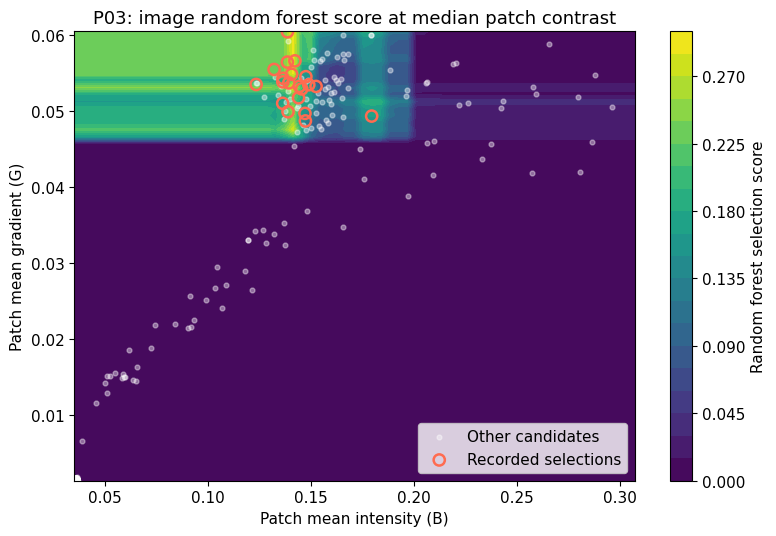

The surface varies brightness and gradient while holding contrast fixed.
Colors represent fitted model scores, not observed spectral rewards.
Final-test decisions remain unused.


In [ ]:
# ============================================================
# BLOCK 8 — INTERPRETING NONLINEAR DECISION MODELS
# ============================================================
# Uses trained models from Blocks 5–7.
# Only validation decisions are analyzed.
# The reserved test set remains untouched.
#
# Goals:
# 1. Find which features each model relies on.
# 2. Compare image and spectral feature reliance.
# 3. Visualize a nonlinear decision surface for P03.
# ============================================================

import matplotlib.pyplot as plt

N_PERMUTATIONS = 25

# Representative models selected from the validation results.
# We include the random trace as a negative control.

inspect_models = [
    (0, "image_spectrum_retrospective", "Linear"),
    (1, "image_only", "RF"),
    (2, "image_spectrum_retrospective", "XGB_rank"),
    (3, "image_only", "Quadratic"),
    (4, "image_only", "RF"),
    (4, "image_spectrum_retrospective", "RF"),
]


# ------------------------------------------------------------
# 1. Unified scoring function
# ------------------------------------------------------------

def score_saved_model(
    tid,
    feature_set,
    algorithm,
    standardized_X,
):
    """
    Score candidates using a previously fitted model.

    Input shape:
        decisions x candidates x features

    Output shape:
        decisions x candidates
    """

    n, k, p = standardized_X.shape

    # Linear conditional-choice model
    if algorithm == "Linear":

        weights = linear_choice_models[
            (tid, feature_set)
        ]["weights"]

        return standardized_X @ weights

    # Quadratic conditional-choice model
    if algorithm == "Quadratic":

        model = quadratic_models[
            (tid, feature_set)
        ]

        Phi, _, _ = make_quadratic_terms(
            standardized_X,
            model["features"],
        )

        return (
            (Phi - model["term_center"])
            / model["term_scale"]
        ) @ model["weights"]

    # Random forest, XGBoost, or another sklearn-style model
    model = benchmark_models[
        (tid, feature_set, algorithm)
    ]["estimator"]

    scores = model.predict(
        standardized_X.reshape(-1, p)
    )

    return np.asarray(
        scores,
        dtype=float,
    ).reshape(n, k)


# ------------------------------------------------------------
# 2. Within-decision permutation reliance
# ------------------------------------------------------------

feature_reliance_rows = []
validation_inputs = {}

rng = np.random.default_rng(42)

for tid, feature_set, algorithm in inspect_models:

    columns = linear_feature_sets[feature_set]

    # Keep complete decisions and their candidate order.
    rows = benchmark_data.loc[
        benchmark_data["trace_id"].eq(tid)
        & benchmark_data["split"].eq("validation")
    ].sort_values([
        "step",
        "candidate_position",
    ])

    label = rows["trace"].iloc[0]
    n_decisions = rows["decision_id"].nunique()

    if len(rows) != n_decisions * N_CANDIDATES:
        raise ValueError(
            f"{label}: inconsistent candidate counts."
        )

    decision_ids = (
        rows["decision_id"]
        .drop_duplicates()
        .to_numpy()
    )

    # Check against the validation predictions saved in Block 7.
    saved = benchmark_scores[
        (tid, feature_set, algorithm)
    ]

    if not np.array_equal(
        decision_ids,
        saved["decision_ids"],
    ):
        raise ValueError(
            f"{label}: validation decision order changed."
        )

    # Recorded selection in each 20-candidate set.
    selected_matrix = (
        rows["selected"]
        .to_numpy()
        .reshape(n_decisions, N_CANDIDATES)
    )

    if not np.all(selected_matrix.sum(axis=1) == 1):
        raise ValueError(
            f"{label}: expected one selection per decision."
        )

    selected_positions = selected_matrix.argmax(axis=1)

    # Use the original training-only feature standardization.
    base_model = linear_choice_models[
        (tid, feature_set)
    ]

    raw_X = (
        rows[columns]
        .to_numpy(dtype=float)
        .reshape(
            n_decisions,
            N_CANDIDATES,
            len(columns),
        )
    )

    Z = (
        raw_X - base_model["center"]
    ) / base_model["scale"]

    # Original validation performance.
    original_scores = score_saved_model(
        tid,
        feature_set,
        algorithm,
        Z,
    )

    # Make sure we reproduce Block 7 exactly.
    if not np.allclose(
        original_scores,
        saved["scores"],
        rtol=1e-6,
        atol=1e-8,
    ):
        raise ValueError(
            f"{label}, {algorithm}: "
            "saved validation scores did not reproduce."
        )

    original_metrics = ranking_metrics(
        original_scores,
        selected_positions,
    )

    validation_inputs[
        (tid, feature_set, algorithm)
    ] = {
        "raw_features": raw_X.copy(),
        "standardized_features": Z.copy(),
        "chosen_positions": selected_positions.copy(),
        "decision_ids": decision_ids.copy(),
    }

    # Measure how much each feature matters.
    for feature_index, feature in enumerate(columns):

        top1_drops = []
        mrr_drops = []

        for repetition in range(N_PERMUTATIONS):

            shuffled = Z.copy()

            # Shuffle this feature among the 20 candidates
            # of EACH decision, preserving decision boundaries.
            for decision_index in range(n_decisions):

                permutation = rng.permutation(
                    N_CANDIDATES
                )

                shuffled[
                    decision_index,
                    :,
                    feature_index,
                ] = Z[
                    decision_index,
                    permutation,
                    feature_index,
                ]

            shuffled_scores = score_saved_model(
                tid,
                feature_set,
                algorithm,
                shuffled,
            )

            shuffled_metrics = ranking_metrics(
                shuffled_scores,
                selected_positions,
            )

            top1_drops.append(
                original_metrics["top1_pct"]
                - shuffled_metrics["top1_pct"]
            )

            mrr_drops.append(
                original_metrics["mrr"]
                - shuffled_metrics["mrr"]
            )

        feature_reliance_rows.append({
            "trace": label,
            "feature_set": feature_set,
            "algorithm": algorithm,
            "feature": feature,
            "baseline_top1_pct": original_metrics["top1_pct"],
            "top1_drop_pp": float(
                np.mean(top1_drops)
            ),
            "mrr_drop": float(
                np.mean(mrr_drops)
            ),
            "mrr_drop_std": float(
                np.std(mrr_drops, ddof=1)
            ),
        })


# ------------------------------------------------------------
# 3. Display feature reliance
# ------------------------------------------------------------

feature_reliance = (
    pd.DataFrame(feature_reliance_rows)
    .sort_values(
        [
            "trace",
            "feature_set",
            "algorithm",
            "mrr_drop",
        ],
        ascending=[
            True,
            True,
            True,
            False,
        ],
    )
    .reset_index(drop=True)
)

print(
    "VALIDATION FEATURE RELIANCE\n"
    "Positive drops mean shuffling the feature hurt ranking."
)

display(
    feature_reliance.round(4)
)


# ------------------------------------------------------------
# 4. Visualize P03 random forest decision surface
# ------------------------------------------------------------
#
# Study the model's dependence on:
#
# B = image mean brightness
# G = image mean gradient
#
# Hold:
#
# C = image standard deviation
#
# fixed at its validation median.
#
# This is a slice through the learned nonlinear function.
# ------------------------------------------------------------

focus_key = (
    4,
    "image_only",
    "RF",
)

focus = validation_inputs[focus_key]

focus_model = linear_choice_models[
    (4, "image_only")
]

raw = focus["raw_features"].reshape(-1, 3)

# Use the central 90% of observed feature values.
brightness_grid = np.linspace(
    *np.quantile(raw[:, 0], [0.05, 0.95]),
    65,
)

gradient_grid = np.linspace(
    *np.quantile(raw[:, 2], [0.05, 0.95]),
    65,
)

BB, GG = np.meshgrid(
    brightness_grid,
    gradient_grid,
)

# Construct hypothetical patches:
# brightness varies, gradient varies, contrast stays fixed.
raw_grid = np.column_stack([
    BB.ravel(),
    np.full(
        BB.size,
        np.median(raw[:, 1]),
    ),
    GG.ravel(),
])

# Apply training-only standardization.
Z_grid = (
    (
        raw_grid - focus_model["center"]
    ) / focus_model["scale"]
).reshape(-1, 1, 3)

surface = score_saved_model(
    *focus_key,
    Z_grid,
).reshape(BB.shape)


# Identify actual P03 selections.
selected = np.zeros(
    focus["raw_features"].shape[:2],
    dtype=bool,
)

selected[
    np.arange(len(selected)),
    focus["chosen_positions"],
] = True

selected = selected.ravel()


# Plot the nonlinear selection-score surface.
fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

contours = ax.contourf(
    BB,
    GG,
    surface,
    levels=20,
    cmap="viridis",
)

fig.colorbar(
    contours,
    ax=ax,
    label="Random forest selection score",
)

# All other validation candidates.
ax.scatter(
    raw[~selected, 0],
    raw[~selected, 2],
    s=12,
    color="white",
    alpha=0.4,
    label="Other candidates",
)

# Candidates P03 actually selected.
ax.scatter(
    raw[selected, 0],
    raw[selected, 2],
    s=65,
    facecolors="none",
    edgecolors="#ff6b50",
    linewidths=1.8,
    label="Recorded selections",
)

ax.set(
    xlabel="Patch mean intensity (B)",
    ylabel="Patch mean gradient (G)",
    title=(
        "P03: image random forest score "
        "at median patch contrast"
    ),
)

ax.set_xlim(
    brightness_grid.min(),
    brightness_grid.max(),
)

ax.set_ylim(
    gradient_grid.min(),
    gradient_grid.max(),
)

ax.legend(loc="best")

plt.tight_layout()
plt.show()

print(
    "The surface varies brightness and gradient "
    "while holding contrast fixed."
)
print(
    "Colors represent fitted model scores, "
    "not observed spectral rewards."
)
print(
    "Final-test decisions remain unused."
)


trace_P03_eels | imitate RF | depth-3 rule
Thresholds below use ORIGINAL feature units:
|--- G <= 0.04657
|   |--- C <= 0.00169
|   |   |--- C <= 0.00168
|   |   |   |--- value: [0.00574]
|   |   |--- C >  0.00168
|   |   |   |--- value: [0.03284]
|   |--- C >  0.00169
|   |   |--- G <= 0.00143
|   |   |   |--- value: [0.00670]
|   |   |--- G >  0.00143
|   |   |   |--- value: [0.00047]
|--- G >  0.04657
|   |--- B <= 0.14452
|   |   |--- C <= 0.06690
|   |   |   |--- value: [0.28443]
|   |   |--- C >  0.06690
|   |   |   |--- value: [0.65108]
|   |--- B >  0.14452
|   |   |--- B <= 0.19862
|   |   |   |--- value: [0.12565]
|   |   |--- B >  0.19862
|   |   |   |--- value: [0.00212]


eels_ucb_trace | imitate XGB_rank | depth-3 rule
Thresholds below use ORIGINAL feature units:
|--- H <= -319.77536
|   |--- G <= 0.04274
|   |   |--- H <= -352.22446
|   |   |   |--- value: [1.23141]
|   |   |--- H >  -352.22446
|   |   |   |--- value: [0.34445]
|   |--- G >  0.04274
|   |   |--- L <= -4

,trace,features,teacher,rule,leaves,top1_pct,top3_pct,mrr,teacher_top1_agreement_pct,teacher_score_r2,teacher_score_mae
0,trace_P03_eels,image_only,RF,Original model,NaN,75.0000,90.0000,0.8417,100.0000,1.0000,0.0000
1,trace_P03_eels,image_only,RF,Tree depth 2,4.0,46.7222,80.4167,0.6583,56.7222,0.7202,0.0363
2,trace_P03_eels,image_only,RF,Tree depth 3,8.0,59.7500,88.7500,0.7496,69.7500,0.8774,0.0211
3,trace_P03_eels,image_only,RF,Tree depth 4,12.0,56.2500,89.9167,0.7363,61.2500,0.9044,0.0178
4,eels_ucb_trace,image_spectrum_retrospective,XGB_rank,Original model,NaN,50.0000,57.5000,0.5765,100.0000,1.0000,0.0000
5,eels_ucb_trace,image_spectrum_retrospective,XGB_rank,Tree depth 2,4.0,34.8465,49.9286,0.4708,42.5548,0.3969,0.2438
6,eels_ucb_trace,image_spectrum_retrospective,XGB_rank,Tree depth 3,7.0,36.4036,49.9691,0.4801,44.7436,0.4297,0.2339
7,eels_ucb_trace,image_spectrum_retrospective,XGB_rank,Tree depth 4,11.0,36.2821,52.9517,0.4904,47.6710,0.4805,0.2169



Feature symbols: {'B': 'img_mean', 'C': 'img_std', 'G': 'img_mean_gradient', 'R': 'spec_measured_mean_full', 'L': 'spec_measured_low_minus_mid', 'H': 'spec_measured_high_minus_mid'}


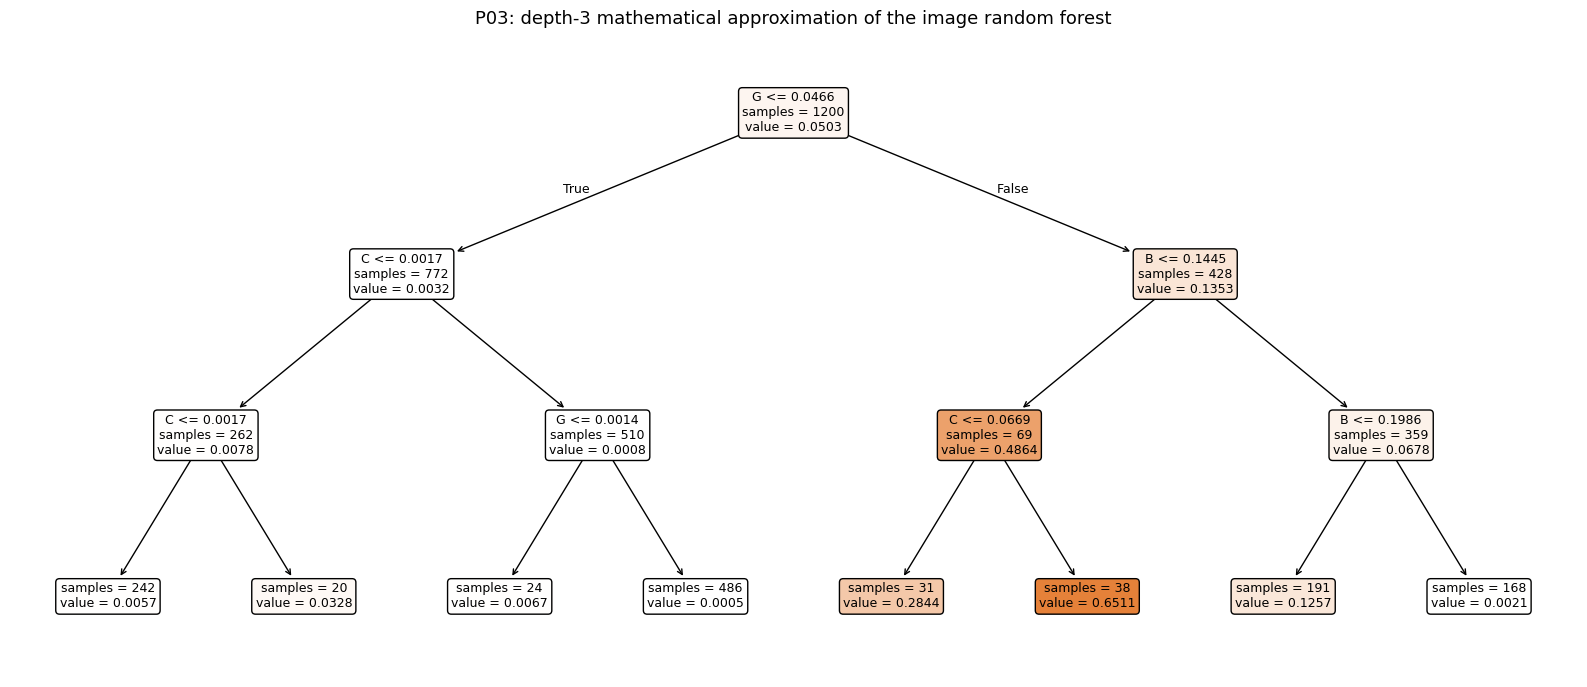

Trees approximate fitted model scores, not the original decision maker's internal mechanism.
A predicted decision is the highest-scoring candidate among the 20 available.
Only training decisions were used to fit these trees.
Final-test decisions remain unused.


In [ ]:
# ============================================================
# BLOCK 9 — EXTRACT INTERPRETABLE NONLINEAR DECISION RULES
# ============================================================
#
# Fit small decision trees to reproduce the scores of our
# previously trained nonlinear models.
#
# Then evaluate:
#   1. Agreement with the original nonlinear model
#   2. Agreement with recorded decisions
#   3. Complexity of the resulting mathematical rules
#
# Training: existing training decisions only
# Evaluation: existing validation decisions only
# Reserved test: untouched
# ============================================================

from sklearn.tree import (
    DecisionTreeRegressor,
    export_text,
    plot_tree,
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
)

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Models to approximate
# ------------------------------------------------------------

distillation_targets = [
    (4, "image_only", "RF"),
    (2, "image_spectrum_retrospective", "XGB_rank"),
]

tree_depths = [2, 3, 4]

MIN_LEAF_SAMPLES = 20


# ------------------------------------------------------------
# 2. Measure agreement between model predictions
# ------------------------------------------------------------

def top_choice_agreement(
    teacher_scores,
    rule_scores,
):
    """
    Expected percentage of matching top choices.

    Ties are handled by averaging over possible
    random tie-breaking.
    """

    teacher_top = (
        teacher_scores
        >= teacher_scores.max(
            axis=1,
            keepdims=True,
        ) - 1e-10
    )

    rule_top = (
        rule_scores
        >= rule_scores.max(
            axis=1,
            keepdims=True,
        ) - 1e-10
    )

    agreement = (
        (teacher_top & rule_top).sum(axis=1)
        /
        (
            teacher_top.sum(axis=1)
            * rule_top.sum(axis=1)
        )
    )

    return float(
        100 * agreement.mean()
    )


# ------------------------------------------------------------
# 3. Train simple trees to imitate nonlinear models
# ------------------------------------------------------------

distilled_trees = {}

distillation_rows = []


for tid, feature_set, teacher_name in distillation_targets:

    key = (
        tid,
        feature_set,
        teacher_name,
    )

    teacher_info = benchmark_models[key]

    teacher = teacher_info["estimator"]

    columns = teacher_info["features"]

    symbols = [
        FEATURE_SYMBOLS[col]
        for col in columns
    ]

    # Retrieve previously prepared training and
    # validation decisions.
    frame = benchmark_data.loc[
        benchmark_data["trace_id"].eq(tid)
    ].sort_values([
        "step",
        "candidate_position",
    ])

    trace_name = frame["trace"].iloc[0]

    train = frame.loc[
        frame["split"].eq("train")
    ]

    valid = frame.loc[
        frame["split"].eq("validation")
    ]

    # Preserve complete 20-candidate decisions.
    if (
        len(train) % N_CANDIDATES
        or len(valid) % N_CANDIDATES
    ):
        raise ValueError(
            f"{trace_name}: incomplete candidate set."
        )

    n_valid = len(valid) // N_CANDIDATES

    selected = (
        valid["selected"]
        .to_numpy()
        .reshape(
            n_valid,
            N_CANDIDATES,
        )
    )

    if not np.all(
        selected.sum(axis=1) == 1
    ):
        raise ValueError(
            f"{trace_name}: invalid validation selections."
        )

    chosen = selected.argmax(axis=1)

    # Verify that we still have the original
    # validation decisions.
    saved = benchmark_scores[key]

    decision_ids = (
        valid["decision_id"]
        .drop_duplicates()
        .to_numpy()
    )

    if not np.array_equal(
        decision_ids,
        saved["decision_ids"],
    ):
        raise ValueError(
            f"{trace_name}: validation order changed."
        )

    if not np.array_equal(
        chosen,
        saved["chosen_positions"],
    ):
        raise ValueError(
            f"{trace_name}: validation selections changed."
        )

    # Use ORIGINAL feature units for the interpretable trees.
    X_train_raw = train[
        columns
    ].to_numpy(dtype=float)

    X_valid_raw = valid[
        columns
    ].to_numpy(dtype=float)

    if (
        not np.isfinite(X_train_raw).all()
        or not np.isfinite(X_valid_raw).all()
    ):
        raise ValueError(
            f"{trace_name}: nonfinite features."
        )

    # The original nonlinear model was trained
    # on standardized features.
    X_train_std = (
        X_train_raw
        - teacher_info["center"]
    ) / teacher_info["scale"]

    # Obtain the original model's training scores.
    teacher_train_scores = (
        teacher.predict(X_train_std)
        .reshape(-1)
    )

    # Reuse the saved validation scores.
    teacher_valid_scores = saved["scores"]

    if not np.isfinite(
        teacher_train_scores
    ).all():
        raise ValueError(
            f"{trace_name}: nonfinite teacher scores."
        )

    # Evaluate the original nonlinear model.
    teacher_metrics = ranking_metrics(
        teacher_valid_scores,
        chosen,
    )

    distillation_rows.append({
        "trace": trace_name,
        "features": feature_set,
        "teacher": teacher_name,
        "rule": "Original model",
        "leaves": np.nan,
        "top1_pct": teacher_metrics["top1_pct"],
        "top3_pct": teacher_metrics["top3_pct"],
        "mrr": teacher_metrics["mrr"],
        "teacher_top1_agreement_pct": 100.0,
        "teacher_score_r2": 1.0,
        "teacher_score_mae": 0.0,
    })

    # --------------------------------------------------------
    # Fit increasingly complex interpretable rules
    # --------------------------------------------------------

    for depth in tree_depths:

        rule = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=MIN_LEAF_SAMPLES,
            random_state=42,
        )

        # Learn to reproduce the original model's scores.
        # No validation data are used for fitting.
        rule.fit(
            X_train_raw,
            teacher_train_scores,
        )

        distilled_trees[
            (*key, depth)
        ] = rule

        # Evaluate on held-out validation decisions.
        rule_scores = (
            rule.predict(X_valid_raw)
            .reshape(
                n_valid,
                N_CANDIDATES,
            )
        )

        metrics = ranking_metrics(
            rule_scores,
            chosen,
        )

        distillation_rows.append({
            "trace": trace_name,
            "features": feature_set,
            "teacher": teacher_name,
            "rule": f"Tree depth {depth}",
            "leaves": int(
                rule.get_n_leaves()
            ),
            "top1_pct": metrics["top1_pct"],
            "top3_pct": metrics["top3_pct"],
            "mrr": metrics["mrr"],

            # Agreement with the original nonlinear model.
            "teacher_top1_agreement_pct": (
                top_choice_agreement(
                    teacher_valid_scores,
                    rule_scores,
                )
            ),

            # How closely the small tree reproduces
            # the original model's numerical scores.
            "teacher_score_r2": float(
                r2_score(
                    teacher_valid_scores.ravel(),
                    rule_scores.ravel(),
                )
            ),

            "teacher_score_mae": float(
                mean_absolute_error(
                    teacher_valid_scores.ravel(),
                    rule_scores.ravel(),
                )
            ),
        })

    # --------------------------------------------------------
    # Print depth-3 mathematical rules
    # --------------------------------------------------------

    depth3 = distilled_trees[
        (*key, 3)
    ]

    print(
        f"\n{trace_name} | "
        f"imitate {teacher_name} | "
        "depth-3 rule"
    )

    print(
        "Thresholds below use ORIGINAL feature units:"
    )

    print(
        export_text(
            depth3,
            feature_names=symbols,
            decimals=5,
        )
    )


# ------------------------------------------------------------
# 4. Compare predictive accuracy and interpretability
# ------------------------------------------------------------

distillation_comparison = pd.DataFrame(
    distillation_rows
)

print(
    "\nVALIDATION — ORIGINAL MODEL "
    "VS SMALL EXPLICIT RULES"
)

display(
    distillation_comparison.round(4)
)


# ------------------------------------------------------------
# 5. Display feature symbols
# ------------------------------------------------------------

symbol_map = {
    FEATURE_SYMBOLS[col]: col
    for _, feature_set, _ in distillation_targets
    for col in linear_feature_sets[feature_set]
}

print(
    "\nFeature symbols:",
    symbol_map,
)


# ------------------------------------------------------------
# 6. Visualize P03's simplified decision tree
# ------------------------------------------------------------

p03_rule = distilled_trees[
    (4, "image_only", "RF", 3)
]

fig, ax = plt.subplots(
    figsize=(16, 7)
)

plot_tree(
    p03_rule,
    feature_names=[
        "B",
        "C",
        "G",
    ],
    filled=True,
    rounded=True,
    impurity=False,
    precision=4,
    fontsize=9,
    ax=ax,
)

ax.set_title(
    "P03: depth-3 mathematical approximation "
    "of the image random forest"
)

plt.tight_layout()
plt.show()


print(
    "Trees approximate fitted model scores, "
    "not the original decision maker's internal mechanism."
)

print(
    "A predicted decision is the highest-scoring "
    "candidate among the 20 available."
)

print(
    "Only training decisions were used to fit these trees."
)

print(
    "Final-test decisions remain unused."
)

In [ ]:
# ============================================================
# BLOCK 10 — RECONSTRUCT RECORDED ACQUISITION FUNCTIONS
# ============================================================
#
# Compare the original algorithm's recorded choices against
# its stored acquisition scores.
#
# Then test whether the UCB scores can be reconstructed
# from predicted_mean and predicted_std.
#
# Uses training and validation decisions only.
# ============================================================

import numpy as np
import pandas as pd

N_CHOICE = 20

algorithm_names = {
    0: "EI",
    1: "Random",
    2: "UCB",
}

logged_records = []


# ------------------------------------------------------------
# 1. Safely extract candidate scores
# ------------------------------------------------------------

def candidate_vector(decision, field):
    """
    Return a finite vector containing 20 candidate values.

    Return None if the field does not have that structure.
    """

    try:
        values = np.asarray(
            decision.get(field),
            dtype=float,
        ).reshape(-1)

    except (TypeError, ValueError):
        return None

    if values.size != N_CHOICE:
        return None

    if not np.isfinite(values).all():
        return None

    return values


# ------------------------------------------------------------
# 2. Extract actual algorithm predictions and scores
# ------------------------------------------------------------

for tid, algorithm in algorithm_names.items():

    trace = traces[tid]

    # Retrieve only train and validation steps.
    split_rows = decision_splits.loc[
        decision_splits["trace_id"].eq(tid)
        & decision_splits["split"].isin([
            "train",
            "validation",
        ])
    ]

    split_by_step = dict(
        zip(
            split_rows["step"],
            split_rows["split"],
        )
    )

    first_allowed = next(
        d for d in trace["decisions"]
        if int(d["step"]) in split_by_step
    )

    print(
        f"\n{algorithm}: stored fields "
        "at an allowed decision"
    )

    for field in [
        "acquisition_scores",
        "predicted_mean",
        "predicted_std",
    ]:

        item = first_allowed.get(field)

        try:
            preview = (
                np.asarray(item)
                .reshape(-1)[:3]
                .tolist()
            )
        except Exception:
            preview = str(
                type(item).__name__
            )

        print(
            f"  {field}: "
            f"shape={np.shape(item)}, "
            f"preview={preview}"
        )

    for decision in trace["decisions"]:

        step = int(decision["step"])

        # Do not inspect reserved-test decisions.
        if step not in split_by_step:
            continue

        selected_position = int(
            decision["selected_position"]
        )

        scores = candidate_vector(
            decision,
            "acquisition_scores",
        )

        mu = candidate_vector(
            decision,
            "predicted_mean",
        )

        std = candidate_vector(
            decision,
            "predicted_std",
        )

        logged_records.append({
            "trace_id": tid,
            "algorithm": algorithm,
            "step": step,
            "split": split_by_step[step],
            "chosen": selected_position,
            "acq": scores,
            "mu": mu,
            "std": std,
        })


# ------------------------------------------------------------
# 3. Check whether recorded selections maximize
#    the logged acquisition scores
# ------------------------------------------------------------

def score_report(items):

    valid = [
        item
        for item in items
        if (
            item["acq"] is not None
            and 0 <= item["chosen"] < N_CHOICE
        )
    ]

    result = {
        "decisions": len(items),
        "usable_score_vectors": len(valid),
        "top1_pct": np.nan,
        "top3_pct": np.nan,
        "mrr": np.nan,
    }

    if valid:

        scores = np.stack([
            item["acq"]
            for item in valid
        ])

        choices = np.array([
            item["chosen"]
            for item in valid
        ], dtype=int)

        result.update(
            ranking_metrics(
                scores,
                choices,
            )
        )

    return result


summary_rows = []

for tid, algorithm in algorithm_names.items():

    for split in [
        "train",
        "validation",
    ]:

        subset = [
            r
            for r in logged_records
            if (
                r["trace_id"] == tid
                and r["split"] == split
            )
        ]

        summary_rows.append({
            "trace": algorithm,
            "split": split,
            **score_report(subset),
        })


native_acquisition_summary = pd.DataFrame(
    summary_rows
)

print(
    "\nLOGGED ACQUISITION SCORES "
    "VS RECORDED SELECTIONS"
)

display(
    native_acquisition_summary.round(4)
)


# ------------------------------------------------------------
# 4. Reconstruct UCB using predicted mean and uncertainty
# ------------------------------------------------------------

ucb_train = [
    r
    for r in logged_records
    if (
        r["trace_id"] == 2
        and r["split"] == "train"
        and r["acq"] is not None
        and r["mu"] is not None
        and r["std"] is not None
    )
]

ucb_valid = [
    r
    for r in logged_records
    if (
        r["trace_id"] == 2
        and r["split"] == "validation"
        and r["acq"] is not None
        and r["mu"] is not None
        and r["std"] is not None
    )
]


if not ucb_train or not ucb_valid:

    print(
        "\nUCB: Missing usable mean/std/acquisition "
        "vectors. Inspect the previews above."
    )

else:

    beta = float(
        traces[2]
        .get("config", {})
        .get("beta", 2.0)
    )

    mu_valid = np.stack([
        r["mu"]
        for r in ucb_valid
    ])

    std_valid = np.stack([
        r["std"]
        for r in ucb_valid
    ])

    logged_valid = np.stack([
        r["acq"]
        for r in ucb_valid
    ])

    chosen_valid = np.array([
        r["chosen"]
        for r in ucb_valid
    ])

    print(
        f"\nUCB: logged beta={beta:g}; "
        f"validation decisions={len(ucb_valid)}"
    )

    # --------------------------------------------------------
    # Compare two common coefficient conventions
    # --------------------------------------------------------

    candidate_formulas = {

        "mean + beta * std":
            mu_valid + beta * std_valid,

        "mean + sqrt(beta) * std":
            mu_valid + np.sqrt(beta) * std_valid,

    }

    formula_rows = []

    for name, predicted in candidate_formulas.items():

        metrics = ranking_metrics(
            predicted,
            chosen_valid,
        )

        formula_rows.append({
            "formula": name,

            "score_mae_vs_logged": float(
                np.mean(
                    np.abs(
                        predicted - logged_valid
                    )
                )
            ),

            "score_max_error_vs_logged": float(
                np.max(
                    np.abs(
                        predicted - logged_valid
                    )
                )
            ),

            **metrics,
        })

    print(
        "\nUCB DIRECT FORMULA CHECK"
    )

    display(
        pd.DataFrame(
            formula_rows
        ).round(6)
    )


    # --------------------------------------------------------
    # 5. Infer the actual coefficients from training logs
    # --------------------------------------------------------
    #
    # Fit:
    #
    # acquisition_score =
    #     a * predicted_mean
    #   + b * predicted_std
    #   + c
    #
    # Fit on training data, evaluate on validation.
    # --------------------------------------------------------

    A_train = np.column_stack([

        np.concatenate([
            r["mu"]
            for r in ucb_train
        ]),

        np.concatenate([
            r["std"]
            for r in ucb_train
        ]),

        np.ones(
            len(ucb_train) * N_CHOICE
        ),

    ])

    y_train = np.concatenate([
        r["acq"]
        for r in ucb_train
    ])

    coefficients, *_ = np.linalg.lstsq(
        A_train,
        y_train,
        rcond=None,
    )

    # Apply the inferred formula to validation.
    A_valid = np.column_stack([

        mu_valid.ravel(),

        std_valid.ravel(),

        np.ones(
            logged_valid.size
        ),

    ])

    fitted_scores = (
        A_valid @ coefficients
    ).reshape(
        logged_valid.shape
    )

    variance = np.sum(
        (
            logged_valid
            - logged_valid.mean()
        ) ** 2
    )

    fitted_r2 = (
        1
        - np.sum(
            (
                logged_valid
                - fitted_scores
            ) ** 2
        ) / variance
        if variance > 0
        else np.nan
    )

    inferred_ratio = (
        coefficients[1] / coefficients[0]
        if abs(coefficients[0]) > 1e-12
        else np.nan
    )

    print(
        "\nUCB COEFFICIENTS FIT ON TRAINING LOGS, "
        "CHECKED ON VALIDATION"
    )

    display(
        pd.DataFrame([{

            "coefficient_mean": coefficients[0],

            "coefficient_std": coefficients[1],

            "intercept": coefficients[2],

            "std_to_mean_ratio": inferred_ratio,

            "validation_R2_vs_logged": fitted_r2,

            "validation_MAE_vs_logged": float(
                np.mean(
                    np.abs(
                        fitted_scores
                        - logged_valid
                    )
                )
            ),

            **ranking_metrics(
                fitted_scores,
                chosen_valid,
            ),

        }]).round(6)
    )


print(
    "\nEI needs the incumbent/best-so-far objective "
    "to test its exact formula."
)

print(
    "All results above exclude reserved-test decisions."
)


EI: stored fields at an allowed decision
  acquisition_scores: shape=(20,), preview=[1.321777904831819, 1.2595041803732778, 1.9340193506720122]
  predicted_mean: shape=(20,), preview=[43.68715286254883, 42.651668548583984, 51.85455322265625]
  predicted_std: shape=(20,), preview=[36.09566116333008, 36.24173355102539, 35.7523078918457]

Random: stored fields at an allowed decision
  acquisition_scores: shape=(20,), preview=[0.6830489532424546, 0.7447621559078171, 0.96750973243421]
  predicted_mean: shape=(20,), preview=[43.68715286254883, 42.651668548583984, 51.85455322265625]
  predicted_std: shape=(20,), preview=[36.09566116333008, 36.24173355102539, 35.7523078918457]

UCB: stored fields at an allowed decision
  acquisition_scores: shape=(20,), preview=[115.87847518920898, 115.13513565063477, 123.35916900634766]
  predicted_mean: shape=(20,), preview=[43.68715286254883, 42.651668548583984, 51.85455322265625]
  predicted_std: shape=(20,), preview=[36.09566116333008, 36.24173355102539,

,trace,split,decisions,usable_score_vectors,top1_pct,top3_pct,mrr
0,EI,train,120,120,100.0,100.0,1.0
1,EI,validation,40,40,100.0,100.0,1.0
2,Random,train,120,120,100.0,100.0,1.0
3,Random,validation,40,40,100.0,100.0,1.0
4,UCB,train,120,120,100.0,100.0,1.0
5,UCB,validation,40,40,100.0,100.0,1.0



UCB: logged beta=2; validation decisions=40

UCB DIRECT FORMULA CHECK


,formula,score_mae_vs_logged,score_max_error_vs_logged,top1_pct,top3_pct,mrr
0,mean + beta * std,0.000000,0.000000,100.0,100.0,1.0
1,mean + sqrt(beta) * std,0.682362,1.197392,100.0,100.0,1.0



UCB COEFFICIENTS FIT ON TRAINING LOGS, CHECKED ON VALIDATION


,coefficient_mean,coefficient_std,intercept,std_to_mean_ratio,validation_R2_vs_logged,validation_MAE_vs_logged,top1_pct,top3_pct,mrr
0,1.0,2.0,0.0,2.0,1.0,0.0,100.0,100.0,1.0



EI needs the incumbent/best-so-far objective to test its exact formula.
All results above exclude reserved-test decisions.


In [ ]:
# ============================================================
# BLOCK 11 — RECONSTRUCT EXPECTED IMPROVEMENT
# ============================================================
#
# Objective:
# Recover the EI acquisition scores mathematically using:
#
#   1. Predicted mean
#   2. Predicted uncertainty
#   3. Best reward observed before each decision
#   4. Exploration parameter xi
#
# Only training and validation decisions are used.
# ============================================================

from scipy.special import ndtr
from sklearn.metrics import r2_score

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Recover rewards from the initial measurements
# ------------------------------------------------------------

ei_trace = traces[0]

ei_config = ei_trace.get(
    "config",
    {},
)

xi = float(
    ei_config.get("xi", 0.01)
)

initial_spectra = ei_trace.get(
    "initial_spectra",
    [],
)

n_channels = analysis_spectra.shape[-1]

initial_rewards = []
bad_initial = []


for i, item in enumerate(initial_spectra):

    try:

        values = np.asarray(
            item,
            dtype=float,
        ).reshape(-1)

        if (
            values.size != n_channels
            or not np.isfinite(values).all()
        ):

            bad_initial.append(
                (i, values.shape)
            )

        else:

            initial_rewards.append(
                float(values.mean())
            )

    except (TypeError, ValueError):

        bad_initial.append(
            (i, type(item).__name__)
        )


expected_initial = int(
    ei_config.get("n_initial", 10)
)

print(
    f"EI initialization: "
    f"{len(initial_rewards)} usable / "
    f"{expected_initial} expected"
)

print(
    f"Unrecognized initial spectra: "
    f"{bad_initial[:3]}"
)


if len(initial_rewards) != expected_initial:

    raise ValueError(
        "Could not recover every initial reward. "
        "Show the initial_spectra entry structure "
        "before continuing."
    )


initial_best = float(
    max(initial_rewards)
)

print(
    f"Initial full-spectrum rewards: "
    f"min={min(initial_rewards):.6f}, "
    f"max={initial_best:.6f}; "
    f"recorded xi={xi:g}"
)


# ------------------------------------------------------------
# 2. Mathematical Expected Improvement function
# ------------------------------------------------------------

def gaussian_expected_improvement(
    mean,
    std,
    threshold,
):
    """
    Expected Improvement for maximizing a reward.

    mean:
        Gaussian predictive mean

    std:
        Gaussian predictive standard deviation

    threshold:
        Best previous reward plus optional exploration offset
    """

    mean = np.asarray(
        mean,
        dtype=float,
    )

    std = np.asarray(
        std,
        dtype=float,
    )

    positive_std = std > 1e-12

    safe_std = np.where(
        positive_std,
        std,
        1.0,
    )

    improvement = mean - threshold

    z = improvement / safe_std

    # Standard normal PDF.
    normal_pdf = (
        np.exp(-0.5 * z**2)
        / np.sqrt(2 * np.pi)
    )

    # Standard normal CDF is ndtr(z).
    result = (
        improvement * ndtr(z)
        + safe_std * normal_pdf
    )

    # Handle zero uncertainty.
    return np.where(
        positive_std,
        result,
        np.maximum(improvement, 0.0),
    )


# ------------------------------------------------------------
# 3. Reconstruct the reward history
# ------------------------------------------------------------

ei_allowed = decision_splits.loc[

    decision_splits["trace_id"].eq(0)

    & decision_splits["split"].isin([
        "train",
        "validation",
    ])

]

ei_split_by_step = dict(
    zip(
        ei_allowed["step"],
        ei_allowed["split"],
    )
)


# Start with the best of the ten initial measurements.
running_best = initial_best

ei_checks = []


for decision in sorted(
    ei_trace["decisions"],
    key=lambda d: int(d["step"]),
):

    step = int(
        decision["step"]
    )

    # Exclude the reserved-test decisions.
    if step not in ei_split_by_step:
        continue

    mu = candidate_vector(
        decision,
        "predicted_mean",
    )

    std = candidate_vector(
        decision,
        "predicted_std",
    )

    logged = candidate_vector(
        decision,
        "acquisition_scores",
    )

    if (
        mu is None
        or std is None
        or logged is None
    ):

        raise ValueError(
            f"EI step {step}: "
            "missing 20-candidate score vectors."
        )

    selected_position = int(
        decision["selected_position"]
    )

    if not 0 <= selected_position < N_CHOICE:

        raise ValueError(
            f"EI step {step}: "
            "invalid selected_position."
        )


    # --------------------------------------------------------
    # Calculate EI BEFORE incorporating the current reward
    # --------------------------------------------------------

    with_xi = gaussian_expected_improvement(
        mu,
        std,
        running_best + xi,
    )

    without_xi = gaussian_expected_improvement(
        mu,
        std,
        running_best,
    )


    ei_checks.append({

        "step": step,

        "split": ei_split_by_step[step],

        "incumbent_before_choice": running_best,

        "chosen": selected_position,

        "logged": logged,

        "EI_with_xi": with_xi,

        "EI_without_xi": without_xi,

    })


    # --------------------------------------------------------
    # Update reward history AFTER calculating EI
    # --------------------------------------------------------

    reward = float(
        decision["selected_reward"]
    )

    if not np.isfinite(reward):

        raise ValueError(
            f"EI step {step}: nonfinite recorded reward."
        )

    running_best = max(
        running_best,
        reward,
    )


# ------------------------------------------------------------
# 4. Compare mathematical EI with stored acquisition scores
# ------------------------------------------------------------

ei_formula_rows = []


for split in [
    "train",
    "validation",
]:

    group = [
        r
        for r in ei_checks
        if r["split"] == split
    ]

    if not group:
        continue

    logged = np.stack([
        r["logged"]
        for r in group
    ])

    chosen = np.array([
        r["chosen"]
        for r in group
    ])


    for label in [
        "EI_with_xi",
        "EI_without_xi",
    ]:

        reconstructed = np.stack([
            r[label]
            for r in group
        ])

        error = np.abs(
            reconstructed - logged
        )

        ei_formula_rows.append({

            "split": split,

            "formula": label,

            "decisions": len(group),

            "score_MAE": float(
                error.mean()
            ),

            "score_max_error": float(
                error.max()
            ),

            "score_R2": float(
                r2_score(
                    logged.ravel(),
                    reconstructed.ravel(),
                )
            ),

            "matching_values_1e_5": int(
                np.isclose(
                    reconstructed,
                    logged,
                    rtol=1e-5,
                    atol=1e-5,
                ).sum()
            ),

            "total_values": int(
                logged.size
            ),

            **ranking_metrics(
                reconstructed,
                chosen,
            ),

        })


ei_formula_comparison = pd.DataFrame(
    ei_formula_rows
)


print(
    "\nEI FORMULA RECONSTRUCTION — "
    "logged scores vs mathematical EI"
)

display(
    ei_formula_comparison.round(6)
)


# ------------------------------------------------------------
# 5. Examine the first decision directly
# ------------------------------------------------------------

print(
    "\nFIRST FIVE CANDIDATES AT EI STEP 1"
)

first = ei_checks[0]

display(
    pd.DataFrame({

        "candidate_position": np.arange(5),

        "logged_acquisition":
            first["logged"][:5],

        "EI_with_xi":
            first["EI_with_xi"][:5],

        "EI_without_xi":
            first["EI_without_xi"][:5],

    }).round(6)
)


print(
    f"\nBest reward before first choice: "
    f"{initial_best:.6f}"
)

print(
    f"Best reward after all allowed choices: "
    f"{running_best:.6f}"
)

print(
    "No reserved-test decision rewards "
    "or scores were used."
)

EI initialization: 10 usable / 10 expected
Unrecognized initial spectra: []
Initial full-spectrum rewards: min=7.460501, max=90.292939; recorded xi=0.01

EI FORMULA RECONSTRUCTION — logged scores vs mathematical EI


,split,formula,decisions,score_MAE,score_max_error,score_R2,matching_values_1e_5,total_values,top1_pct,top3_pct,mrr
0,train,EI_with_xi,120,1130.349674,5576.608224,-1.115254,0,2400,28.458333,39.541667,0.394838
1,train,EI_without_xi,120,1130.349723,5576.608224,-1.115254,0,2400,28.458333,39.541667,0.394838
2,validation,EI_with_xi,40,2735.805645,7125.958365,-3.345353,0,800,9.750000,19.250000,0.220893
3,validation,EI_without_xi,40,2735.805645,7125.958365,-3.345353,0,800,9.750000,19.250000,0.220893



FIRST FIVE CANDIDATES AT EI STEP 1


,candidate_position,logged_acquisition,EI_with_xi,EI_without_xi
0,0,1.321778,1.673459,1.674442
1,1,1.259504,1.598706,1.599649
2,2,1.934019,2.574953,2.576364
3,3,1.238635,1.564929,1.565873
4,4,2.046534,2.732436,2.733967



Best reward before first choice: 90.292939
Best reward after all allowed choices: 143.434265
No reserved-test decision rewards or scores were used.


## 1. Dataset and Decision Traces

We investigated whether recorded EELS measurement decisions can be reconstructed and explained using image features, spectral measurements, and mathematical acquisition functions.

Image dimensions: (66, 152)
Spectral cube: (66, 152, 4198)
Energy channels per spectrum: 4,198
Recorded decisions: 800
Candidate observations: 16,000
Candidates per decision: 20

DECISION SPLITS


split,test_reserved,train,validation
trace,,,
eels_ei_trace,40,120,40
eels_random_trace,40,120,40
eels_ucb_trace,40,120,40
trace_P01_eels_,20,60,20
trace_P03_eels,20,60,20


**Important:** Complete decisions were kept together during chronological splitting. The final 20% of decisions in each trace remains reserved for testing.

## 2. Models and Methods

We started with interpretable mathematical models, then tested more flexible nonlinear algorithms.

,Model,Purpose
0,Uniform,Random-choice reference
1,Linear,Measure individual feature weights
2,Quadratic,Capture squared terms and interactions
3,Random Forest,Learn nonlinear thresholds and interactions
4,Extra Trees,Test randomized tree ensembles
5,Histogram Gradient Boosting,Capture nonlinear feature relationships
6,K-Nearest Neighbors,Test similarity-based decision patterns
7,RBF Support Vector Regression,Learn smooth nonlinear relationships
8,XGBoost Ranking,Optimize rankings within candidate sets


... (22 outputs left out)

## 7. Comparing P01 and P03

P01 and P03 were presented with the same candidate schedule, but their selections differed substantially.

Compared training + validation steps: 80
Same selected location: 11 of 80
Agreement: 13.8%


The participants' different selections and different fitted feature relationships suggest that one universal image-based equation may not describe every decision-maker.

## 8. Final Results Dashboard

The following figure summarizes predictive performance, feature reliance, EI reconstruction, spatial sampling, and the measured EELS spectra.

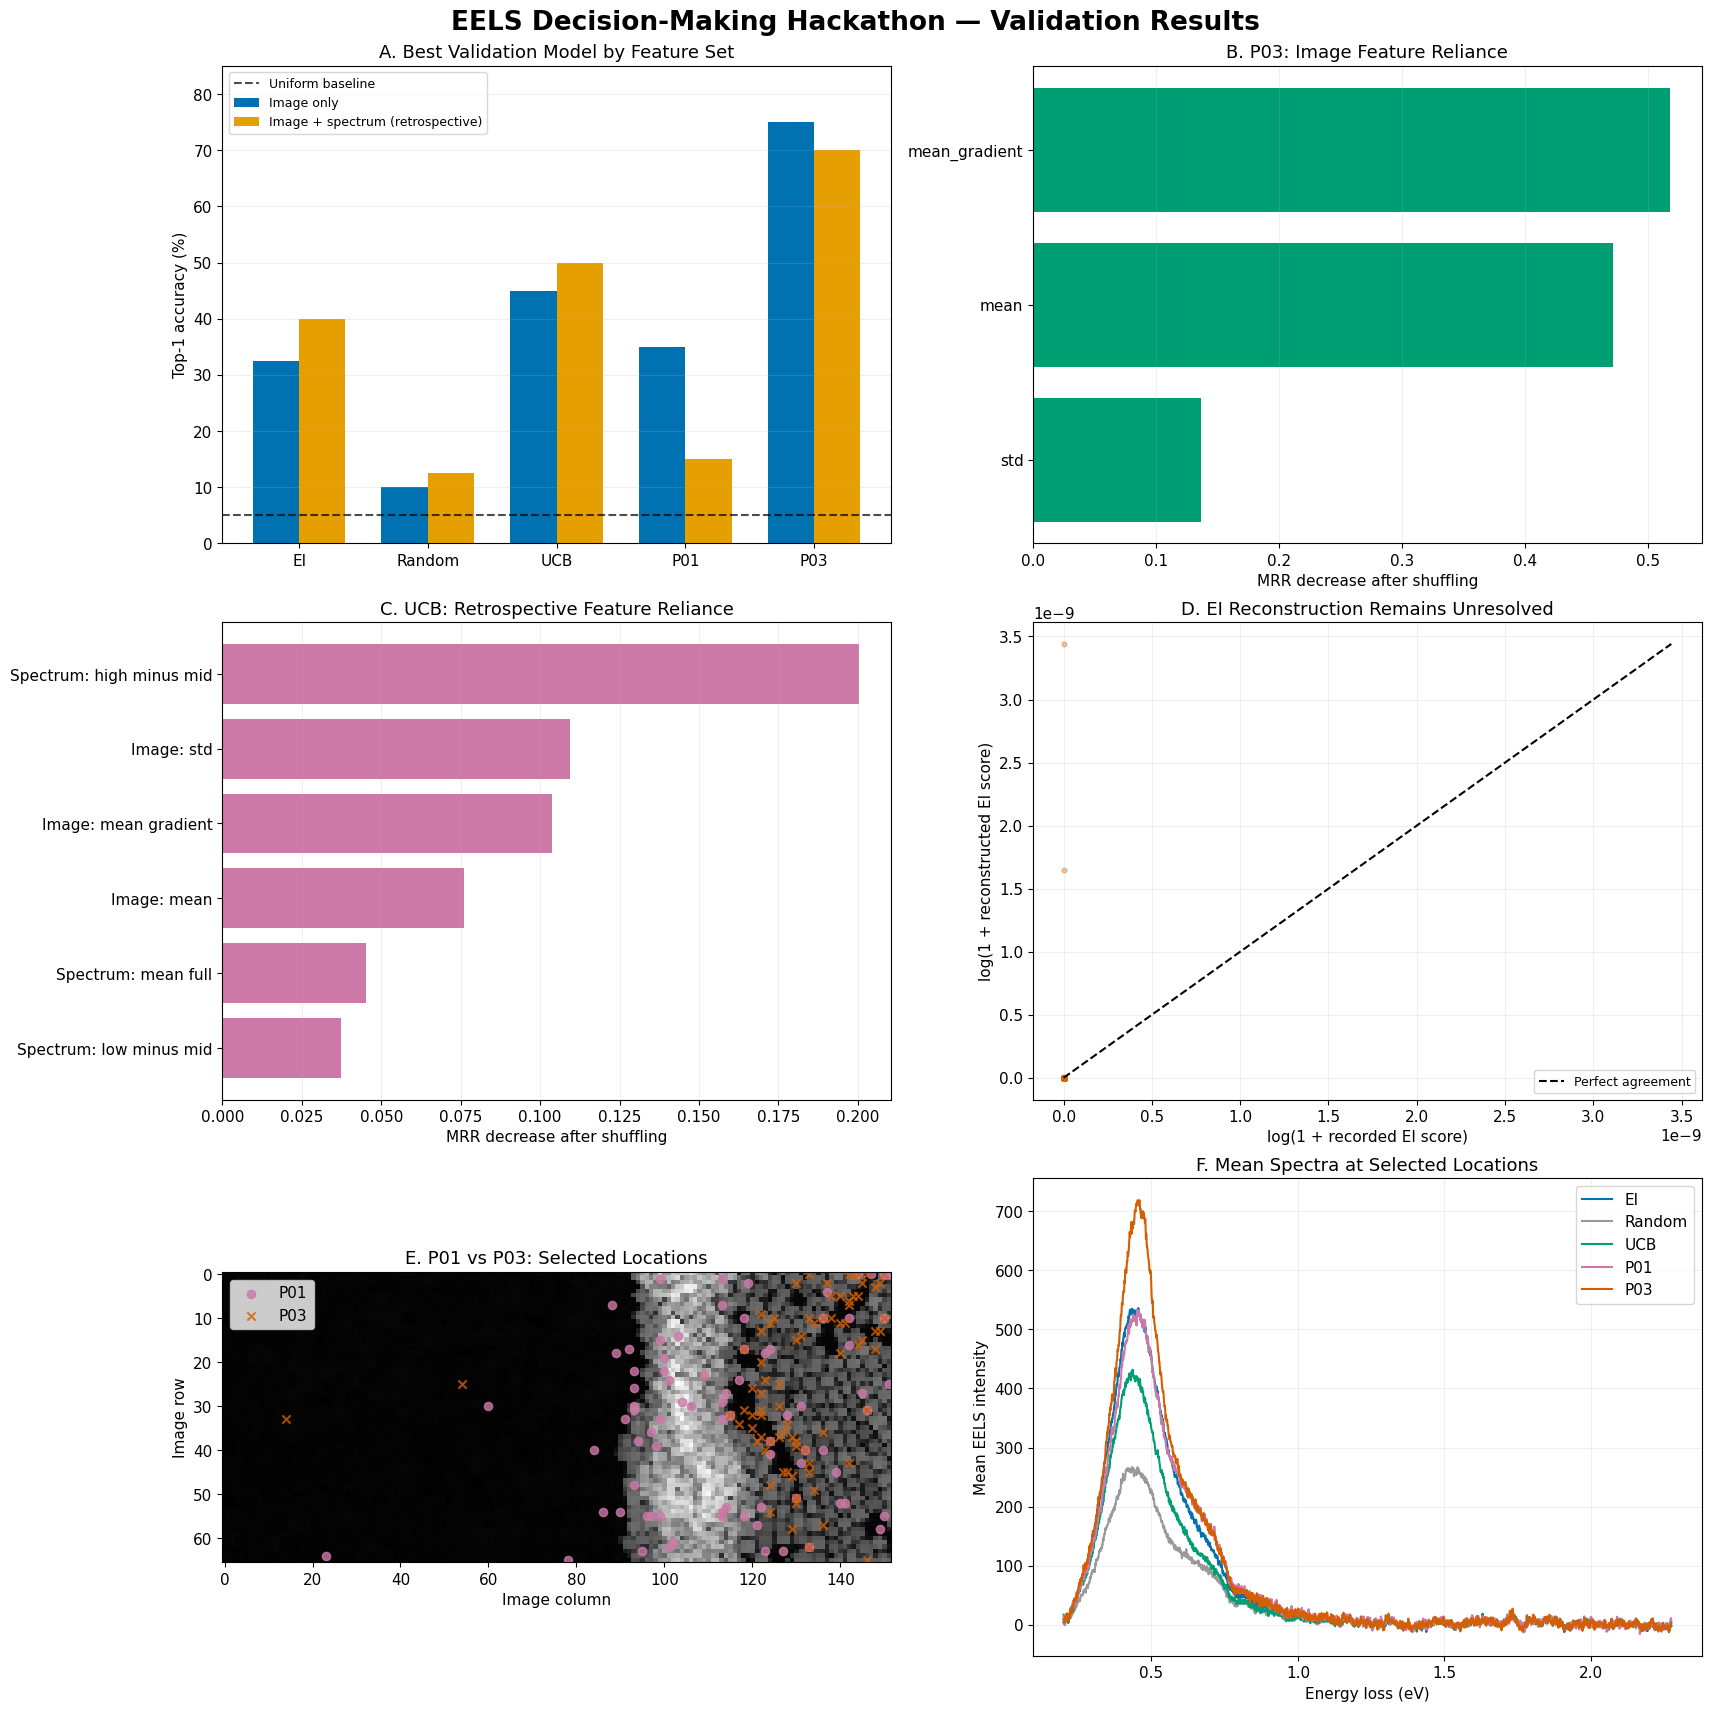

## 9. P03 Interpretable Decision Tree

This tree is our compact approximation of P03's nonlinear image-based selection scores.

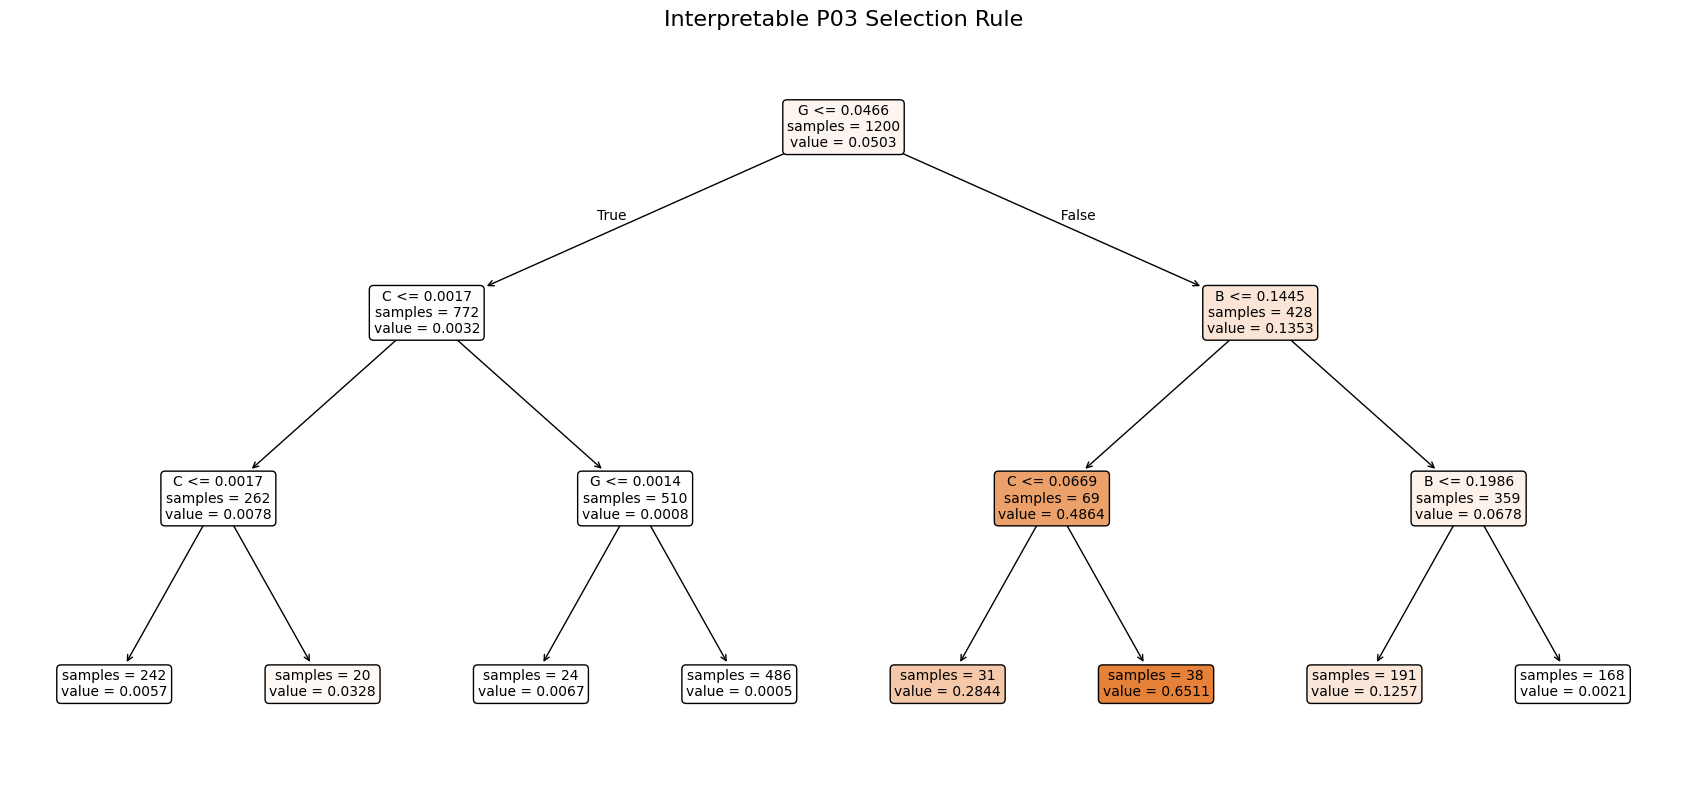

## 10. Final Conclusions

These are the main points to communicate during the hackathon presentation.

**1. The recorded decisions can be modeled.**

Image features predict some selection patterns substantially better than uniform random ranking.

**2. Nonlinear relationships matter.**

P03's random forest achieved 75% validation top-1 accuracy, outperforming its linear model.

**3. Some nonlinear behavior can be simplified.**

A depth-3 decision tree retained approximately 60% top-1 accuracy using eight explicit rules.

**4. Spectral measurements provide useful retrospective information.**

Certain spectral descriptors improve the reconstruction of EI and UCB selections, although their availability before each decision has not been established.

**5. UCB's acquisition calculation was recovered.**

The recorded UCB scores equal predicted mean plus twice the predicted standard deviation.

**6. EI is not yet mathematically reconstructed.**

The standard Gaussian EI formula using the reconstructed running-best reward did not match the stored acquisition scores.

**7. Explaining behavior is different from recovering the original algorithm.**

A regression model can imitate a selection without reproducing the computation that produced it.

**8. Further validation is needed.**

All reported predictive results are exploratory validation results. The reserved test decisions have not been used.

## 11. Generated Figures



1. EELS_Hackathon_Final_Dashboard.png
2. EELS_P03_Interpretable_Decision_Tree.png

Summary complete.


In [ ]:
# ============================================================
# BLOCK 12 — COMPLETE HACKATHON SUMMARY AND VISUALIZATIONS
# ============================================================
#
# EELS Decision-Making Hackathon
#
# Goal:
# Understand how image information, EELS spectra, and
# model predictions relate to recorded candidate selections.
#
# Includes:
# 1. Dataset summary
# 2. Model comparison
# 3. Feature interpretation
# 4. Mathematical decision rules
# 5. Acquisition-function reconstruction
# 6. Final figures
# 7. Conclusions
#
# All predictive results use TRAIN + VALIDATION only.
# Reserved final-test decisions are not evaluated.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import export_text, plot_tree
from IPython.display import display, Markdown


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def heading(title, description=""):

    display(
        Markdown(
            f"## {title}\n\n{description}"
        )
    )


def subheading(title, description=""):

    display(
        Markdown(
            f"### {title}\n\n{description}"
        )
    )


short_names = {
    "eels_ei_trace": "EI",
    "eels_random_trace": "Random",
    "eels_ucb_trace": "UCB",
    "trace_P01_eels_": "P01",
    "trace_P03_eels": "P03",
}

trace_order = list(short_names.keys())

colors = {
    "EI": "#0072B2",
    "Random": "#999999",
    "UCB": "#009E73",
    "P01": "#CC79A7",
    "P03": "#D55E00",
}


# ============================================================
# SECTION 1 — DATASET
# ============================================================

heading(
    "1. Dataset and Decision Traces",
    "We investigated whether recorded EELS measurement "
    "decisions can be reconstructed and explained using "
    "image features, spectral measurements, and "
    "mathematical acquisition functions."
)

image_shape = analysis_spectra.shape[:2]

spectral_channels = analysis_spectra.shape[-1]

n_total_decisions = decision_splits[
    "decision_id"
].nunique()

n_candidate_rows = len(candidate_features)

print(
    f"Image dimensions: {image_shape}"
)

print(
    f"Spectral cube: {analysis_spectra.shape}"
)

print(
    f"Energy channels per spectrum: {spectral_channels:,}"
)

print(
    f"Recorded decisions: {n_total_decisions:,}"
)

print(
    f"Candidate observations: {n_candidate_rows:,}"
)

print(
    f"Candidates per decision: {N_CANDIDATES}"
)


split_summary = pd.crosstab(
    decision_splits["trace"],
    decision_splits["split"],
)

print("\nDECISION SPLITS")

display(split_summary)


display(
    Markdown(
        "**Important:** Complete decisions were kept together "
        "during chronological splitting. The final 20% of "
        "decisions in each trace remains reserved for testing."
    )
)


# ============================================================
# SECTION 2 — WHAT WE TESTED
# ============================================================

heading(
    "2. Models and Methods",
    "We started with interpretable mathematical models, "
    "then tested more flexible nonlinear algorithms."
)


methods = pd.DataFrame({

    "Model": [
        "Uniform",
        "Linear",
        "Quadratic",
        "Random Forest",
        "Extra Trees",
        "Histogram Gradient Boosting",
        "K-Nearest Neighbors",
        "RBF Support Vector Regression",
        "XGBoost Ranking",
    ],

    "Purpose": [
        "Random-choice reference",
        "Measure individual feature weights",
        "Capture squared terms and interactions",
        "Learn nonlinear thresholds and interactions",
        "Test randomized tree ensembles",
        "Capture nonlinear feature relationships",
        "Test similarity-based decision patterns",
        "Learn smooth nonlinear relationships",
        "Optimize rankings within candidate sets",
    ],

})

display(methods)


display(
    Markdown(
        "Two feature sets were compared:\n\n"
        "- **Image only:** patch brightness, standard deviation, "
        "and mean gradient.\n"
        "- **Image + spectrum (retrospective):** image features "
        "plus full-spectrum mean intensity and spectral-band differences.\n\n"
        "The spectral features for unselected candidates were extracted "
        "from the complete dataset afterward. Their predictive value "
        "does not establish that those spectra were available before "
        "the original decisions."
    )
)


# ============================================================
# SECTION 3 — BEST PREDICTIVE MODELS
# ============================================================

heading(
    "3. Predicting Recorded Decisions",
    "Each model ranked the same 20 candidates presented "
    "at a recorded decision. Top-1 accuracy measures how "
    "often the model ranked the actual selection first."
)


best_models = (
    benchmark_validation.loc[
        benchmark_validation["algorithm"] != "Uniform"
    ]
    .sort_values(
        [
            "trace",
            "feature_set",
            "top1_pct",
            "mrr",
        ],
        ascending=[
            True,
            True,
            False,
            False,
        ],
    )
    .drop_duplicates([
        "trace",
        "feature_set",
    ])
    .reset_index(drop=True)
)


best_models_display = best_models[
    [
        "trace",
        "feature_set",
        "algorithm",
        "top1_pct",
        "top3_pct",
        "mrr",
    ]
].copy()

best_models_display["trace"] = (
    best_models_display["trace"]
    .map(short_names)
)

print("\nBEST VALIDATION MODELS")

display(
    best_models_display.round(3)
)


display(
    Markdown(
        "**Reference performance:** With 20 candidates, "
        "uniform random ranking gives approximately "
        "5% top-1 accuracy, 15% top-3 accuracy, "
        "and an MRR of 0.180.\n\n"
        "**Interpretation:** These are exploratory validation "
        "comparisons. Because many models were evaluated, "
        "the best observed validation accuracy may be optimistic."
    )
)


# ============================================================
# SECTION 4 — NONLINEAR FEATURE INTERPRETATION
# ============================================================

heading(
    "4. Which Features Influence the Rankings?",
    "We measured feature reliance by shuffling one feature "
    "among the 20 candidates within each decision. "
    "A larger decrease in MRR means the fitted model "
    "depends more strongly on information from that feature."
)


feature_groups = [
    (0, "image_spectrum_retrospective", "Linear"),
    (1, "image_only", "RF"),
    (2, "image_spectrum_retrospective", "XGB_rank"),
    (3, "image_only", "Quadratic"),
    (4, "image_only", "RF"),
]

importance_rows = []

for tid, feature_set, algorithm in feature_groups:

    trace_name = trace_order[tid]

    group = feature_reliance.loc[
        (feature_reliance["trace"] == trace_name)
        & (feature_reliance["feature_set"] == feature_set)
        & (feature_reliance["algorithm"] == algorithm)
    ]

    group = group.nlargest(
        3,
        "mrr_drop",
    )

    importance_rows.append(group)


important_features = pd.concat(
    importance_rows,
    ignore_index=True,
)

important_features_display = important_features[
    [
        "trace",
        "algorithm",
        "feature",
        "mrr_drop",
    ]
].copy()

important_features_display["trace"] = (
    important_features_display["trace"]
    .map(short_names)
)

print("\nTHREE MOST INFLUENTIAL FEATURES PER SELECTED MODEL")

display(
    important_features_display.round(4)
)


display(
    Markdown(
        "**Main observations:**\n\n"
        "- P03's image random forest relies heavily on "
        "brightness and gradient.\n"
        "- P01's quadratic model relies most strongly on "
        "image standard deviation.\n"
        "- UCB's retrospective XGBoost model relies strongly "
        "on the high-minus-middle spectral-band feature.\n"
        "- The random trace shows little convincing evidence "
        "of stable, learnable feature preferences.\n\n"
        "These are properties of our fitted models, "
        "not causal explanations of the original decisions."
    )
)


# ============================================================
# SECTION 5 — INTERPRETABLE P03 EQUATION
# ============================================================

heading(
    "5. Extracting a Mathematical Decision Rule",
    "The P03 random forest reproduced 75% of validation "
    "selections. We then fitted a small decision tree "
    "to approximate its selection scores."
)


p03_comparison = distillation_comparison.loc[
    (distillation_comparison["trace"] == "trace_P03_eels")
][
    [
        "rule",
        "leaves",
        "top1_pct",
        "top3_pct",
        "mrr",
        "teacher_score_r2",
    ]
]

print("\nP03: COMPLEX MODEL VS INTERPRETABLE TREES")

display(
    p03_comparison.round(4)
)


p03_rule = distilled_trees[
    (4, "image_only", "RF", 3)
]


print("\nP03 DEPTH-3 MATHEMATICAL RULE")

print(
    "B = image brightness\n"
    "C = image standard deviation\n"
    "G = image mean gradient\n"
)

print(
    export_text(
        p03_rule,
        feature_names=["B", "C", "G"],
        decimals=5,
    )
)


display(
    Markdown(
        "**Interpretation:** The simplified P03 model "
        "generally assigns higher selection scores to "
        "patches with relatively large gradients and "
        "particular combinations of brightness and contrast.\n\n"
        "The depth-3 tree uses at most eight terminal rules. "
        "It is less accurate than the random forest, but "
        "its thresholds can be written explicitly."
    )
)


# ============================================================
# SECTION 6 — ORIGINAL ACQUISITION FUNCTIONS
# ============================================================

heading(
    "6. Reconstructing the Original Algorithmic Logic",
    "Unlike the retrospective regression models, "
    "the algorithm traces contain the predicted means, "
    "uncertainties, and acquisition scores used "
    "during candidate selection."
)


print("\nRECORDED ACQUISITION SCORES")

display(
    native_acquisition_summary.round(4)
)


# Confirm UCB numerically using validation only.
ucb_records = [
    r
    for r in logged_records
    if (
        r["trace_id"] == 2
        and r["split"] == "validation"
    )
]

ucb_mu = np.stack([
    r["mu"] for r in ucb_records
])

ucb_std = np.stack([
    r["std"] for r in ucb_records
])

ucb_logged = np.stack([
    r["acq"] for r in ucb_records
])

ucb_beta = float(
    traces[2]["config"]["beta"]
)

ucb_reconstructed = (
    ucb_mu
    + ucb_beta * ucb_std
)

ucb_error = np.abs(
    ucb_reconstructed - ucb_logged
)


subheading(
    "6A. Upper Confidence Bound",
    "The recorded UCB acquisition scores were reconstructed "
    "using the predicted mean and uncertainty."
)

display(
    Markdown(
        rf"""
\[
\boxed{{\mathrm{{UCB}}(x)=\mu(x)+{ucb_beta:g}\sigma(x)}}
\]

- Validation score MAE: **{ucb_error.mean():.8f}**
- Maximum absolute score error: **{ucb_error.max():.8f}**
- Validation decisions: **{len(ucb_records)}**
"""
    )
)


# EI results
ei_validation = ei_formula_comparison.loc[
    ei_formula_comparison["split"].eq("validation")
]

subheading(
    "6B. Expected Improvement",
    "The logged EI scores reproduce the recorded selections, "
    "but the standard Gaussian EI formula using the "
    "reconstructed running-best reward does not reproduce "
    "the logged acquisition scores."
)

display(
    ei_validation.round(4)
)


display(
    Markdown(
        "**Interpretation:** UCB's acquisition calculation "
        "was recovered exactly. EI remains unresolved. "
        "Possible explanations include a different incumbent, "
        "normalization, or another implementation detail.\n\n"
        "The random trace also selects the maximum of its "
        "logged acquisition scores. Those scores are random, "
        "so this does not imply a deterministic feature-based rule."
    )
)


# ============================================================
# SECTION 7 — PARTICIPANT COMPARISON
# ============================================================

heading(
    "7. Comparing P01 and P03",
    "P01 and P03 were presented with the same candidate "
    "schedule, but their selections differed substantially."
)


p01_selections = benchmark_data.loc[
    (benchmark_data["trace_id"] == 3)
    & (benchmark_data["selected"] == 1)
][
    ["step", "dataset_index"]
]

p03_selections = benchmark_data.loc[
    (benchmark_data["trace_id"] == 4)
    & (benchmark_data["selected"] == 1)
][
    ["step", "dataset_index"]
]

human_comparison = p01_selections.merge(
    p03_selections,
    on="step",
    suffixes=("_P01", "_P03"),
)

same_selection = (
    human_comparison["dataset_index_P01"]
    == human_comparison["dataset_index_P03"]
)

print(
    f"Compared training + validation steps: "
    f"{len(human_comparison)}"
)

print(
    f"Same selected location: "
    f"{same_selection.sum()} "
    f"of {len(human_comparison)}"
)

print(
    f"Agreement: "
    f"{100 * same_selection.mean():.1f}%"
)


display(
    Markdown(
        "The participants' different selections and "
        "different fitted feature relationships suggest "
        "that one universal image-based equation may not "
        "describe every decision-maker."
    )
)


# ============================================================
# SECTION 8 — SUMMARY DASHBOARD
# ============================================================

heading(
    "8. Final Results Dashboard",
    "The following figure summarizes predictive performance, "
    "feature reliance, EI reconstruction, spatial sampling, "
    "and the measured EELS spectra."
)


fig, axes = plt.subplots(
    3,
    2,
    figsize=(17, 17),
    constrained_layout=True,
)

fig.suptitle(
    "EELS Decision-Making Hackathon — Validation Results",
    fontsize=19,
    fontweight="bold",
)


# ------------------------------------------------------------
# PLOT A — BEST VALIDATION ACCURACY
# ------------------------------------------------------------

ax = axes[0, 0]

img_accuracy = []
spec_accuracy = []


for trace_name in trace_order:

    image_row = best_models.loc[
        (best_models["trace"] == trace_name)
        & (best_models["feature_set"] == "image_only")
    ].iloc[0]

    spec_row = best_models.loc[
        (best_models["trace"] == trace_name)
        & (
            best_models["feature_set"]
            == "image_spectrum_retrospective"
        )
    ].iloc[0]

    img_accuracy.append(
        image_row["top1_pct"]
    )

    spec_accuracy.append(
        spec_row["top1_pct"]
    )


x = np.arange(5)
width = 0.36

ax.bar(
    x - width / 2,
    img_accuracy,
    width,
    color="#0072B2",
    label="Image only",
)

ax.bar(
    x + width / 2,
    spec_accuracy,
    width,
    color="#E69F00",
    label="Image + spectrum (retrospective)",
)

ax.axhline(
    5,
    color="black",
    linestyle="--",
    alpha=0.7,
    label="Uniform baseline",
)

ax.set_xticks(x)
ax.set_xticklabels(list(short_names.values()))

ax.set_ylabel("Top-1 accuracy (%)")
ax.set_ylim(0, 85)

ax.set_title(
    "A. Best Validation Model by Feature Set"
)

ax.legend(fontsize=9)

ax.grid(axis="y", alpha=0.2)


# ------------------------------------------------------------
# PLOT B — P03 FEATURE RELIANCE
# ------------------------------------------------------------

ax = axes[0, 1]

p03_importance = feature_reliance.loc[
    (feature_reliance["trace"] == "trace_P03_eels")
    & (feature_reliance["feature_set"] == "image_only")
    & (feature_reliance["algorithm"] == "RF")
].sort_values("mrr_drop")


ax.barh(
    p03_importance["feature"].str.replace(
        "img_",
        "",
        regex=False,
    ),
    p03_importance["mrr_drop"],
    color="#009E73",
)

ax.set_xlabel("MRR decrease after shuffling")

ax.set_title(
    "B. P03: Image Feature Reliance"
)

ax.grid(axis="x", alpha=0.2)


# ------------------------------------------------------------
# PLOT C — UCB FEATURE RELIANCE
# ------------------------------------------------------------

ax = axes[1, 0]

ucb_importance = feature_reliance.loc[
    (feature_reliance["trace"] == "eels_ucb_trace")
    & (
        feature_reliance["feature_set"]
        == "image_spectrum_retrospective"
    )
    & (feature_reliance["algorithm"] == "XGB_rank")
].sort_values("mrr_drop")


def readable_feature(name):

    return (
        name
        .replace("spec_measured_", "Spectrum: ")
        .replace("img_", "Image: ")
        .replace("_", " ")
    )


ax.barh(
    [
        readable_feature(f)
        for f in ucb_importance["feature"]
    ],
    ucb_importance["mrr_drop"],
    color="#CC79A7",
)

ax.set_xlabel("MRR decrease after shuffling")

ax.set_title(
    "C. UCB: Retrospective Feature Reliance"
)

ax.grid(axis="x", alpha=0.2)


# ------------------------------------------------------------
# PLOT D — EI RECONSTRUCTION ERROR
# ------------------------------------------------------------

ax = axes[1, 1]

ei_valid = [
    r
    for r in ei_checks
    if r["split"] == "validation"
]

recorded = np.concatenate([
    r["logged"]
    for r in ei_valid
])

predicted = np.concatenate([
    r["EI_with_xi"]
    for r in ei_valid
])


# Log transformation makes the large range readable.
recorded_plot = np.log1p(
    np.maximum(recorded, 0)
)

predicted_plot = np.log1p(
    np.maximum(predicted, 0)
)


ax.scatter(
    recorded_plot,
    predicted_plot,
    s=12,
    alpha=0.35,
    color="#D55E00",
)

limit = max(
    recorded_plot.max(),
    predicted_plot.max(),
)

ax.plot(
    [0, limit],
    [0, limit],
    "k--",
    label="Perfect agreement",
)

ax.set_xlabel("log(1 + recorded EI score)")

ax.set_ylabel("log(1 + reconstructed EI score)")

ax.set_title(
    "D. EI Reconstruction Remains Unresolved"
)

ax.legend(fontsize=9)

ax.grid(alpha=0.2)


# ------------------------------------------------------------
# PLOT E — SPATIAL SELECTIONS
# ------------------------------------------------------------

ax = axes[2, 0]

ax.imshow(
    image,
    cmap="gray",
    origin="upper",
)

for tid, name, marker in [
    (3, "P01", "o"),
    (4, "P03", "x"),
]:

    points = benchmark_data.loc[
        (benchmark_data["trace_id"] == tid)
        & (benchmark_data["selected"] == 1)
    ]

    ax.scatter(
        points["col"],
        points["row"],
        s=35,
        marker=marker,
        color=colors[name],
        label=name,
        alpha=0.8,
    )

ax.set_title(
    "E. P01 vs P03: Selected Locations"
)

ax.set_xlabel("Image column")

ax.set_ylabel("Image row")

ax.legend()


# ------------------------------------------------------------
# PLOT F — AVERAGE SELECTED EELS SPECTRA
# ------------------------------------------------------------

ax = axes[2, 1]

energy_axis = np.asarray(
    traces[0]["decisions"][0]["selected_axis"],
    dtype=float,
).reshape(-1)

flat_spectra = analysis_spectra.reshape(
    -1,
    spectral_channels,
)


for tid, trace_name in enumerate(trace_order):

    selected_rows = benchmark_data.loc[
        (benchmark_data["trace_id"] == tid)
        & (benchmark_data["selected"] == 1)
    ]

    indices = selected_rows[
        "dataset_index"
    ].to_numpy(dtype=int)

    mean_spectrum = (
        flat_spectra[indices]
        .mean(axis=0)
    )

    label = short_names[trace_name]

    ax.plot(
        energy_axis,
        mean_spectrum,
        label=label,
        color=colors[label],
        linewidth=1.5,
    )


ax.set_xlabel("Energy loss (eV)")

ax.set_ylabel("Mean EELS intensity")

ax.set_title(
    "F. Mean Spectra at Selected Locations"
)

ax.legend()

ax.grid(alpha=0.2)


# ------------------------------------------------------------
# SAVE DASHBOARD
# ------------------------------------------------------------

fig.savefig(
    "EELS_Hackathon_Final_Dashboard.png",
    dpi=250,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# SECTION 9 — INTERPRETABLE TREE FIGURE
# ============================================================

heading(
    "9. P03 Interpretable Decision Tree",
    "This tree is our compact approximation of "
    "P03's nonlinear image-based selection scores."
)


fig_tree, ax_tree = plt.subplots(
    figsize=(17, 8)
)

plot_tree(
    p03_rule,
    feature_names=["B", "C", "G"],
    filled=True,
    rounded=True,
    impurity=False,
    precision=4,
    fontsize=10,
    ax=ax_tree,
)

ax_tree.set_title(
    "Interpretable P03 Selection Rule",
    fontsize=16,
)

fig_tree.tight_layout()

fig_tree.savefig(
    "EELS_P03_Interpretable_Decision_Tree.png",
    dpi=250,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# SECTION 10 — FINAL TAKEAWAYS
# ============================================================

heading(
    "10. Final Conclusions",
    "These are the main points to communicate "
    "during the hackathon presentation."
)


conclusions = [

    (
        "1. The recorded decisions can be modeled.",
        "Image features predict some selection patterns "
        "substantially better than uniform random ranking.",
    ),

    (
        "2. Nonlinear relationships matter.",
        "P03's random forest achieved 75% validation "
        "top-1 accuracy, outperforming its linear model.",
    ),

    (
        "3. Some nonlinear behavior can be simplified.",
        "A depth-3 decision tree retained approximately "
        "60% top-1 accuracy using eight explicit rules.",
    ),

    (
        "4. Spectral measurements provide useful "
        "retrospective information.",
        "Certain spectral descriptors improve the "
        "reconstruction of EI and UCB selections, "
        "although their availability before each "
        "decision has not been established.",
    ),

    (
        "5. UCB's acquisition calculation was recovered.",
        "The recorded UCB scores equal predicted mean "
        "plus twice the predicted standard deviation.",
    ),

    (
        "6. EI is not yet mathematically reconstructed.",
        "The standard Gaussian EI formula using the "
        "reconstructed running-best reward did not "
        "match the stored acquisition scores.",
    ),

    (
        "7. Explaining behavior is different from "
        "recovering the original algorithm.",
        "A regression model can imitate a selection "
        "without reproducing the computation that "
        "produced it.",
    ),

    (
        "8. Further validation is needed.",
        "All reported predictive results are exploratory "
        "validation results. The reserved test decisions "
        "have not been used.",
    ),

]


for title, explanation in conclusions:

    display(
        Markdown(
            f"**{title}**\n\n{explanation}"
        )
    )


# ============================================================
# FINAL DELIVERABLES
# ============================================================

heading(
    "11. Generated Figures"
)

print(
    "1. EELS_Hackathon_Final_Dashboard.png"
)

print(
    "2. EELS_P03_Interpretable_Decision_Tree.png"
)

print(
    "\nSummary complete."
)